# Deep Learning Project — CIFAR-10 Image Classification



## 1. Imports and configuration


In [3]:

import os
os.environ["PYTHONHASHSEED"] = "0"


In [4]:
import os
import random as python_random
import pickle

import numpy as np
from matplotlib import pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
python_random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

BATCH_SIZE = 128
EPOCHS = 30
LEARNING_RATE = 1e-3
NUM_CLASSES = 10
IMG_SIZE = 32
TL_IMG_SIZE = 96
VAL_SIZE = 5000

# Update this path if the CIFAR-10 Python batch files are stored elsewhere.
DATA_DIR = r"C:\Users\filip\Desktop\Deep Learning\cifar-10-batches-py"

OUT_DIR = "./outputs_tf"
os.makedirs(OUT_DIR, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)


TensorFlow: 2.21.0
GPU available: False


## 2. Loading CIFAR-10 from Python batch files




In [5]:
def unpickle(file_path):
    """Load a CIFAR-10 Python batch file."""
    with open(file_path, "rb") as fo:
        data_dict = pickle.load(fo, encoding="latin1")
    return data_dict


def reshape_cifar_batch(data):
    """Convert CIFAR-10 flat vectors into RGB images."""
    images = data.reshape(-1, 3, 32, 32)
    images = images.transpose(0, 2, 3, 1)
    return images.astype("float32")


def load_cifar10_from_py(data_dir=DATA_DIR):
    """Load CIFAR-10 from local Python batch files."""
    x_batches, y_batches = [], []

    for i in range(1, 6):
        batch_path = os.path.join(data_dir, f"data_batch_{i}")
        batch = unpickle(batch_path)

        x_batches.append(reshape_cifar_batch(batch["data"]))
        y_batches.append(np.array(batch["labels"], dtype="int32"))

    test_batch = unpickle(os.path.join(data_dir, "test_batch"))
    x_test = reshape_cifar_batch(test_batch["data"])
    y_test = np.array(test_batch["labels"], dtype="int32")

    x_train = np.concatenate(x_batches, axis=0)
    y_train = np.concatenate(y_batches, axis=0)

    meta = unpickle(os.path.join(data_dir, "batches.meta"))
    class_names = meta["label_names"]

    return (x_train, y_train), (x_test, y_test), class_names


(x_train_full, y_train_full), (x_test, y_test), class_names = load_cifar10_from_py(DATA_DIR)

print("Loaded CIFAR-10 from local Python batch files")
print("Training full:", x_train_full.shape, y_train_full.shape)
print("Test:", x_test.shape, y_test.shape)
print("Classes:", class_names)


Loaded CIFAR-10 from local Python batch files
Training full: (50000, 32, 32, 3) (50000,)
Test: (10000, 32, 32, 3) (10000,)
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 3. Train / validation / test split


- 45,000 images for training;
- 5,000 images for validation;
- 10,000 images for final testing.


In [6]:
rng = np.random.default_rng(SEED)
indices = rng.permutation(len(x_train_full))

val_indices = indices[:VAL_SIZE]
train_indices = indices[VAL_SIZE:]

x_train = x_train_full[train_indices]
y_train = y_train_full[train_indices]
x_val = x_train_full[val_indices]
y_val = y_train_full[val_indices]

print("Train:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test:", x_test.shape, y_test.shape)


Train: (45000, 32, 32, 3) (45000,)
Validation: (5000, 32, 32, 3) (5000,)
Test: (10000, 32, 32, 3) (10000,)


## 4. Dataset exploration


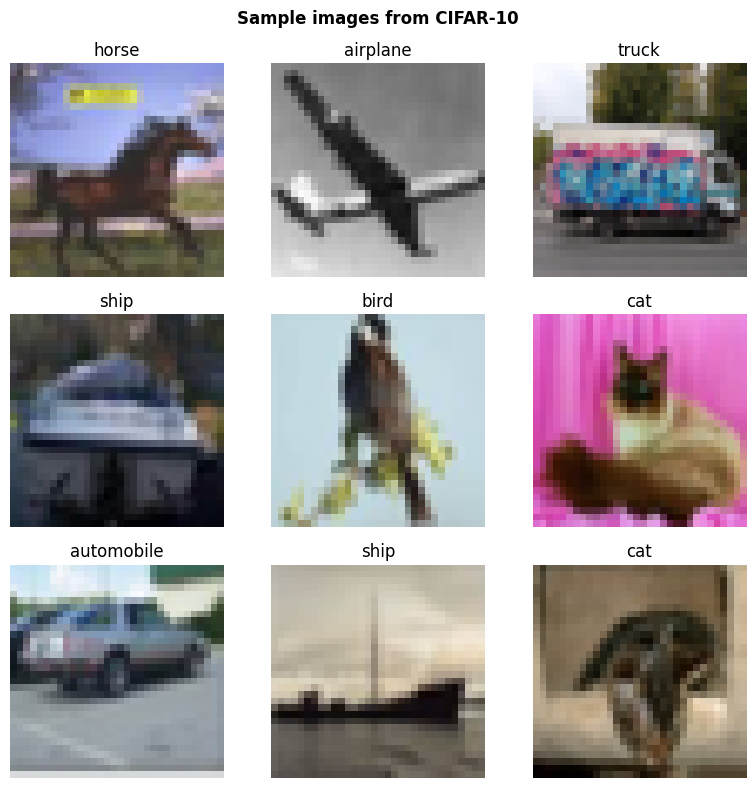

In [7]:
def show_samples(x, y, class_names, n=9):
    plt.figure(figsize=(8, 8))
    for i in range(n):
        ax = plt.subplot(3, 3, i + 1)
        ax.imshow(x[i].astype("uint8"))
        ax.set_title(class_names[int(y[i])])
        ax.axis("off")

    plt.suptitle("Sample images from CIFAR-10", fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "sample_images.png"), dpi=120, bbox_inches="tight")
    plt.show()


show_samples(x_train, y_train, class_names)


## 5. Preprocessing and `tf.data` pipeline

For the custom CNNs:

- `Rescaling(1./255)` brings pixel values from `[0, 255]` to `[0, 1]`;
- `Normalization` standardizes the input using statistics computed on the training set;
- data augmentation is applied only during training and only when explicitly enabled inside the model.


In [8]:
normalizer = layers.Normalization(axis=-1, name="normalization")
normalizer.adapt(x_train / 255.0)

augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(height_factor=0.10, width_factor=0.10, fill_mode="reflect"),
    layers.RandomContrast(0.10),
], name="data_augmentation")


def make_dataset(x, y, training=False, batch_size=BATCH_SIZE):
    ds = tf.data.Dataset.from_tensor_slices((x, y))

    if training:
        ds = ds.shuffle(buffer_size=len(x), seed=SEED, reshuffle_each_iteration=True)

    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds


train_ds = make_dataset(x_train, y_train, training=True)
val_ds = make_dataset(x_val, y_val, training=False)
test_ds = make_dataset(x_test, y_test, training=False)

print(train_ds)


<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 32, 32, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>


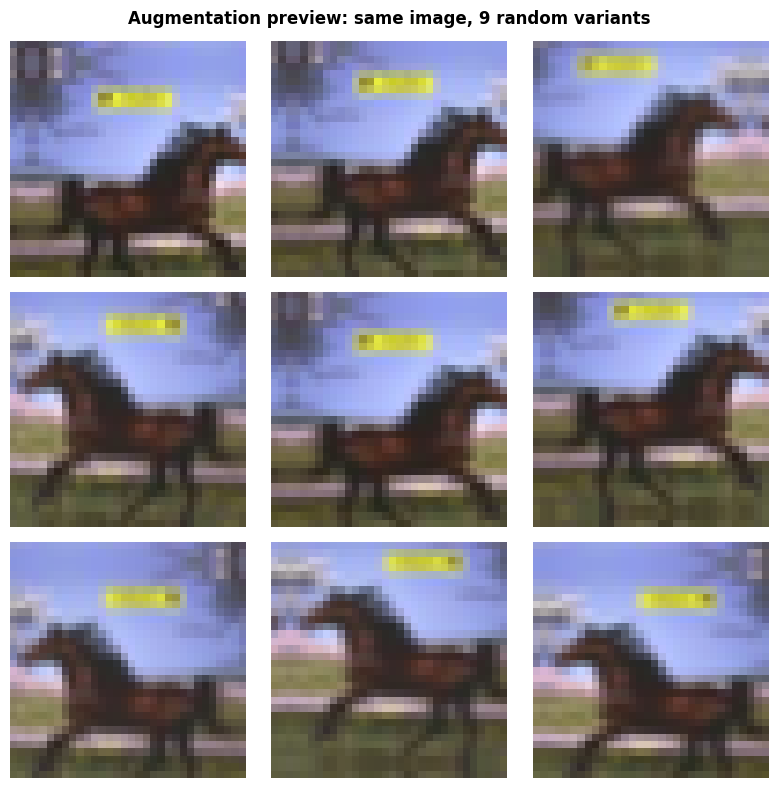

In [9]:
def preview_augmentation(x, augmentation_layer, n=9):
    base = x[0:1] / 255.0

    plt.figure(figsize=(8, 8))
    for i in range(n):
        augmented = augmentation_layer(base, training=True)[0].numpy()
        ax = plt.subplot(3, 3, i + 1)
        ax.imshow(np.clip(augmented, 0, 1))
        ax.axis("off")

    plt.suptitle("Augmentation preview: same image, 9 random variants", fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "augmentation_preview.png"), dpi=120, bbox_inches="tight")
    plt.show()


preview_augmentation(x_train, augmentation)


## 6. Training and evaluation utilities


In [10]:
def compile_model(model, learning_rate=LEARNING_RATE):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")]
    )
    return model


def get_callbacks(model_name, patience=6):
    return [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=patience,
            restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=1e-6
        ),
        keras.callbacks.ModelCheckpoint(
            filepath=os.path.join(OUT_DIR, f"{model_name}.keras"),
            monitor="val_loss",
            save_best_only=True
        )
    ]


def train_model(model, model_name, train_ds=train_ds, val_ds=val_ds, epochs=EPOCHS,
                learning_rate=LEARNING_RATE, patience=6):
    compile_model(model, learning_rate)
    model.summary()

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        callbacks=get_callbacks(model_name, patience),
        verbose=1
    )

    return history


def train_model_clip(model, model_name, train_ds=train_ds, val_ds=val_ds,
                     epochs=EPOCHS, learning_rate=5e-4, patience=7):
    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate,
            clipnorm=1.0
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    model.summary()

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        callbacks=get_callbacks(model_name, patience),
        verbose=1
    )

    return history

def plot_history(history, title):
    h = history.history
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(h["loss"], label="train")
    plt.plot(h["val_loss"], label="validation")
    plt.title(f"{title} — Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.subplot(1, 2, 2)
    plt.plot(h["accuracy"], label="train")
    plt.plot(h["val_accuracy"], label="validation")
    plt.title(f"{title} — Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    filename = f"{title.replace(' ', '_').lower()}_curves.png"
    plt.savefig(os.path.join(OUT_DIR, filename), dpi=120, bbox_inches="tight")
    plt.show()


def plot_history_wide(history, title, loss_ylim=(0.0, 0.9), acc_ylim=(0.70, 1.00)):
    """Re-plot an existing training history with wider y-axis limits."""
    h = history.history
    epochs_range = range(len(h["loss"]))

    plt.figure(figsize=(14, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, h["loss"], label="train")
    plt.plot(epochs_range, h["val_loss"], label="validation")
    plt.title(f"{title} — Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.ylim(*loss_ylim)
    plt.grid(alpha=0.3)
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, h["accuracy"], label="train")
    plt.plot(epochs_range, h["val_accuracy"], label="validation")
    plt.title(f"{title} — Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.ylim(*acc_ylim)
    plt.grid(alpha=0.3)
    plt.legend()

    plt.tight_layout()
    plt.show()


def evaluate_model(model, dataset, y_true=None, model_name="model"):
    test_loss, test_acc = model.evaluate(dataset, verbose=0)
    print(f"{model_name} | test loss: {test_loss:.4f} | test accuracy: {test_acc:.4f}")

    probabilities = model.predict(dataset, verbose=0)
    y_pred = np.argmax(probabilities, axis=1)

    if y_true is None:
        y_true = np.concatenate([y.numpy() for _, y in dataset], axis=0)

    print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
    return y_pred, probabilities, test_acc


## 7. Model 1 — Shallow baseline CNN


In [11]:
def build_shallow_cnn(use_augmentation=False):
    inputs = keras.Input(shape=(32, 32, 3))

    x = layers.Rescaling(1./255)(inputs)

    if use_augmentation:
        x = augmentation(x)

    x = normalizer(x)

    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Flatten()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.30)(x)

    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    return keras.Model(inputs, outputs, name="Shallow_CNN")


Model: "Shallow_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 32, 32, 3)      │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,048,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,070,801 (4.08 MB)

 Trainable params: 1,070,794 (4.08 MB)

 Non-trainable params: 7 (32.00 B)

Epoch 1/30


C:\Users\filip\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


352/352 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - accuracy: 0.5012 - loss: 1.4039 - val_accuracy: 0.5990 - val_loss: 1.1046 - learning_rate: 0.0010
Epoch 2/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.6418 - loss: 1.0224 - val_accuracy: 0.6658 - val_loss: 0.9483 - learning_rate: 0.0010
Epoch 3/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.6972 - loss: 0.8702 - val_accuracy: 0.6856 - val_loss: 0.8871 - learning_rate: 0.0010
Epoch 4/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.7358 - loss: 0.7599 - val_accuracy: 0.7048 - val_loss: 0.8372 - learning_rate: 0.0010
Epoch 5/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.7680 - loss: 0.6649 - val_accuracy: 0.7058 - val_loss: 0.8211 - learning_rate: 0.0010
Epoch 6/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.7980 - loss: 0.5794 - val_accuracy: 0.7110 - val_loss: 0.8247 - learning_rate: 0.0010
Epoch 7/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.8247 - loss: 0.5024 - val

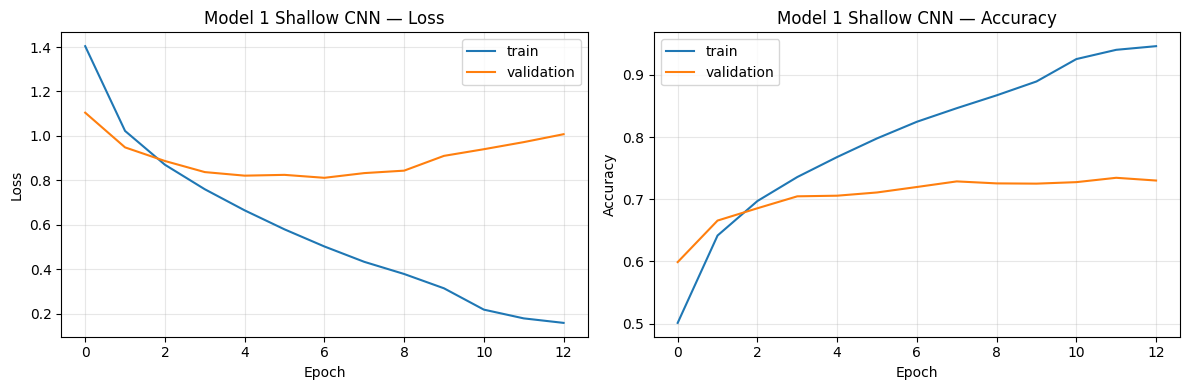

Model 1 — Shallow CNN | test loss: 0.8199 | test accuracy: 0.7283
              precision    recall  f1-score   support

    airplane      0.777     0.761     0.769      1000
  automobile      0.884     0.727     0.798      1000
        bird      0.682     0.625     0.652      1000
         cat      0.547     0.565     0.556      1000
        deer      0.643     0.730     0.684      1000
         dog      0.661     0.610     0.634      1000
        frog      0.810     0.765     0.787      1000
       horse      0.748     0.815     0.780      1000
        ship      0.818     0.847     0.832      1000
       truck      0.748     0.838     0.791      1000

    accuracy                          0.728     10000
   macro avg      0.732     0.728     0.728     10000
weighted avg      0.732     0.728     0.728     10000



In [12]:
model_1 = build_shallow_cnn(use_augmentation=False)

history_1 = train_model(
    model_1,
    "model_1_shallow_cnn",
    patience=6
)

plot_history(
    history_1,
    "Model 1 Shallow CNN"
)

preds_1, probs_1, acc_1 = evaluate_model(
    model_1,
    test_ds,
    y_true=y_test,
    model_name="Model 1 — Shallow CNN"
)


## 8. Model 1b — Shallow CNN with data augmentation


Model: "Shallow_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 32, 32, 3)      │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     1,048,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,070,801 (4.08 MB)

 Trainable params: 1,070,794 (4.08 MB)

 Non-trainable params: 7 (32.00 B)

Epoch 1/30


C:\Users\filip\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


352/352 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - accuracy: 0.4427 - loss: 1.5461 - val_accuracy: 0.5872 - val_loss: 1.1648 - learning_rate: 0.0010
Epoch 2/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - accuracy: 0.5725 - loss: 1.2075 - val_accuracy: 0.6350 - val_loss: 1.0073 - learning_rate: 0.0010
Epoch 3/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.6178 - loss: 1.0800 - val_accuracy: 0.6556 - val_loss: 0.9525 - learning_rate: 0.0010
Epoch 4/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.6438 - loss: 1.0097 - val_accuracy: 0.6816 - val_loss: 0.8886 - learning_rate: 0.0010
Epoch 5/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.6658 - loss: 0.9530 - val_accuracy: 0.7082 - val_loss: 0.8347 - learning_rate: 0.0010
Epoch 6/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.6796 - loss: 0.9107 - val_accuracy: 0.7234 - val_loss: 0.7805 - learning_rate: 0.0010
Epoch 7/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.6910 - loss: 0.8807

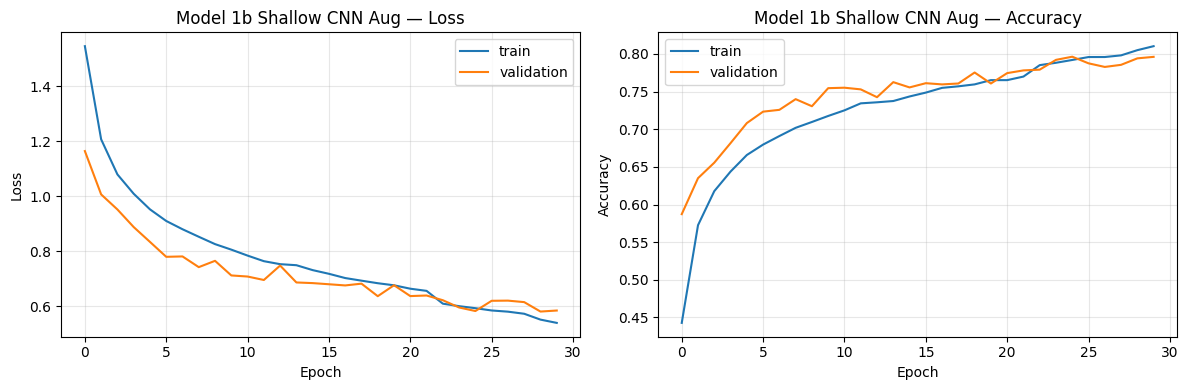

Model 1b — Shallow CNN + Augmentation | test loss: 0.6020 | test accuracy: 0.7970
              precision    recall  f1-score   support

    airplane      0.804     0.847     0.825      1000
  automobile      0.876     0.926     0.900      1000
        bird      0.739     0.699     0.718      1000
         cat      0.678     0.557     0.612      1000
        deer      0.770     0.757     0.763      1000
         dog      0.737     0.677     0.706      1000
        frog      0.732     0.910     0.811      1000
       horse      0.841     0.860     0.851      1000
        ship      0.895     0.873     0.884      1000
       truck      0.880     0.864     0.872      1000

    accuracy                          0.797     10000
   macro avg      0.795     0.797     0.794     10000
weighted avg      0.795     0.797     0.794     10000



In [13]:
model_1_aug = build_shallow_cnn(use_augmentation=True)

history_1_aug = train_model(
    model_1_aug,
    "model_1b_shallow_cnn_aug",
    patience=6
)

plot_history(
    history_1_aug,
    "Model 1b Shallow CNN Aug"
)

preds_1_aug, probs_1_aug, acc_1_aug = evaluate_model(
    model_1_aug,
    test_ds,
    y_true=y_test,
    model_name="Model 1b — Shallow CNN + Augmentation"
)


## 9. Model 2 — Deep CNN


In [14]:
def conv_block(x, filters, pool=True, weight_decay=1e-4):
    x = layers.Conv2D(
        filters,
        3,
        padding="same",
        use_bias=False,
        kernel_regularizer=keras.regularizers.l2(weight_decay)
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.Conv2D(
        filters,
        3,
        padding="same",
        use_bias=False,
        kernel_regularizer=keras.regularizers.l2(weight_decay)
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    if pool:
        x = layers.MaxPooling2D()(x)

    return x


def build_deep_cnn(use_augmentation=True):
    inputs = keras.Input(shape=(32, 32, 3))

    x = layers.Rescaling(1./255)(inputs)

    if use_augmentation:
        x = augmentation(x)

    x = normalizer(x)

    x = conv_block(x, 64, pool=True)
    x = conv_block(x, 128, pool=True)
    x = conv_block(x, 256, pool=True)
    x = conv_block(x, 256, pool=False)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(512, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.50)(x)

    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    return keras.Model(inputs, outputs, name="Deep_CNN_BN_Dropout")


Model: "Deep_CNN_BN_Dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 32, 32, 3)      │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │         1,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 8, 8, 256)      │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 8, 8, 256)      │       589,824 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 2,468,049 (9.41 MB)

 Trainable params: 2,464,202 (9.40 MB)

 Non-trainable params: 3,847 (15.03 KB)

Epoch 1/30


C:\Users\filip\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


352/352 ━━━━━━━━━━━━━━━━━━━━ 217s 603ms/step - accuracy: 0.4674 - loss: 1.6402 - val_accuracy: 0.4710 - val_loss: 1.8469 - learning_rate: 0.0010
Epoch 2/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 190s 538ms/step - accuracy: 0.6647 - loss: 1.1027 - val_accuracy: 0.6190 - val_loss: 1.3911 - learning_rate: 0.0010
Epoch 3/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 173s 492ms/step - accuracy: 0.7381 - loss: 0.9043 - val_accuracy: 0.6892 - val_loss: 1.0712 - learning_rate: 0.0010
Epoch 4/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 156s 444ms/step - accuracy: 0.7790 - loss: 0.8072 - val_accuracy: 0.7112 - val_loss: 1.0260 - learning_rate: 0.0010
Epoch 5/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 157s 446ms/step - accuracy: 0.7993 - loss: 0.7462 - val_accuracy: 0.7570 - val_loss: 0.8952 - learning_rate: 0.0010
Epoch 6/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 160s 454ms/step - accuracy: 0.8168 - loss: 0.7042 - val_accuracy: 0.6680 - val_loss: 1.2519 - learning_rate: 0.0010
Epoch 7/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 157s 447ms/step - accuracy: 0.8284 

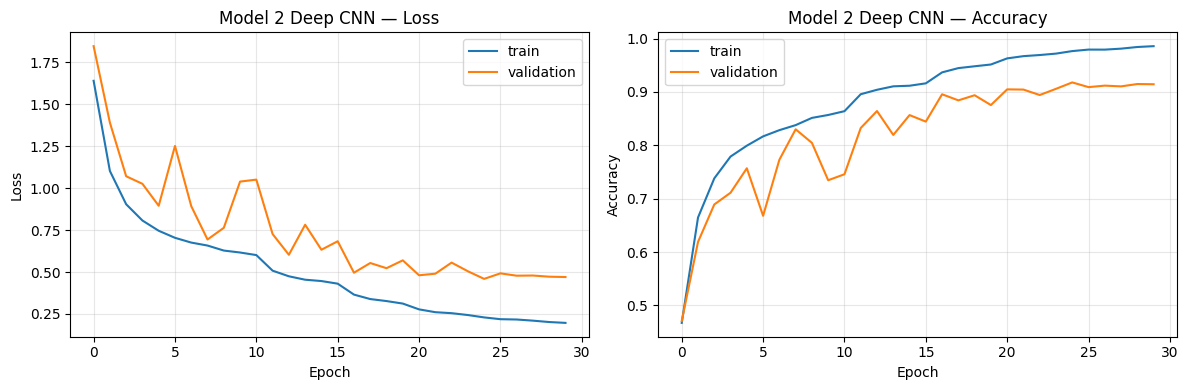

Model 2 — Deep CNN | test loss: 0.4662 | test accuracy: 0.9121
              precision    recall  f1-score   support

    airplane      0.912     0.928     0.920      1000
  automobile      0.965     0.962     0.963      1000
        bird      0.902     0.868     0.885      1000
         cat      0.819     0.831     0.825      1000
        deer      0.911     0.903     0.907      1000
         dog      0.896     0.832     0.863      1000
        frog      0.885     0.957     0.920      1000
       horse      0.934     0.941     0.937      1000
        ship      0.950     0.950     0.950      1000
       truck      0.950     0.949     0.949      1000

    accuracy                          0.912     10000
   macro avg      0.912     0.912     0.912     10000
weighted avg      0.912     0.912     0.912     10000



In [15]:
model_2 = build_deep_cnn(use_augmentation=True)

history_2 = train_model(
    model_2,
    "model_2_deep_cnn",
    patience=7
)

plot_history(
    history_2,
    "Model 2 Deep CNN"
)

preds_2, probs_2, acc_2 = evaluate_model(
    model_2,
    test_ds,
    y_true=y_test,
    model_name="Model 2 — Deep CNN"
)


## 10. Model 2 experiments — Learning rate, clipping and regularization


Model: "Deep_CNN_BN_Dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_4 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 32, 32, 3)      │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 32, 32, 64)     │         1,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_18 (Activation)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_19 (Activation)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_20 (Activation)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_21 (Activation)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 8, 8, 256)      │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_22          │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_22 (Activation)      │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 8, 8, 256)      │       589,824 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 2,468,049 (9.41 MB)

 Trainable params: 2,464,202 (9.40 MB)

 Non-trainable params: 3,847 (15.03 KB)

Epoch 1/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 208s 577ms/step - accuracy: 0.4842 - loss: 1.6051 - val_accuracy: 0.5234 - val_loss: 1.4721 - learning_rate: 5.0000e-04
Epoch 2/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 205s 582ms/step - accuracy: 0.6697 - loss: 1.0695 - val_accuracy: 0.6396 - val_loss: 1.1687 - learning_rate: 5.0000e-04
Epoch 3/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 177s 502ms/step - accuracy: 0.7422 - loss: 0.8785 - val_accuracy: 0.7338 - val_loss: 0.9309 - learning_rate: 5.0000e-04
Epoch 4/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 176s 501ms/step - accuracy: 0.7803 - loss: 0.7744 - val_accuracy: 0.6954 - val_loss: 1.0451 - learning_rate: 5.0000e-04
Epoch 5/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 169s 480ms/step - accuracy: 0.8042 - loss: 0.7102 - val_accuracy: 0.7734 - val_loss: 0.7884 - learning_rate: 5.0000e-04
Epoch 6/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 178s 506ms/step - accuracy: 0.8203 - loss: 0.6657 - val_accuracy: 0.7464 - val_loss: 0.9546 - learning_rate: 5.0000e-04
Epoch 7/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 

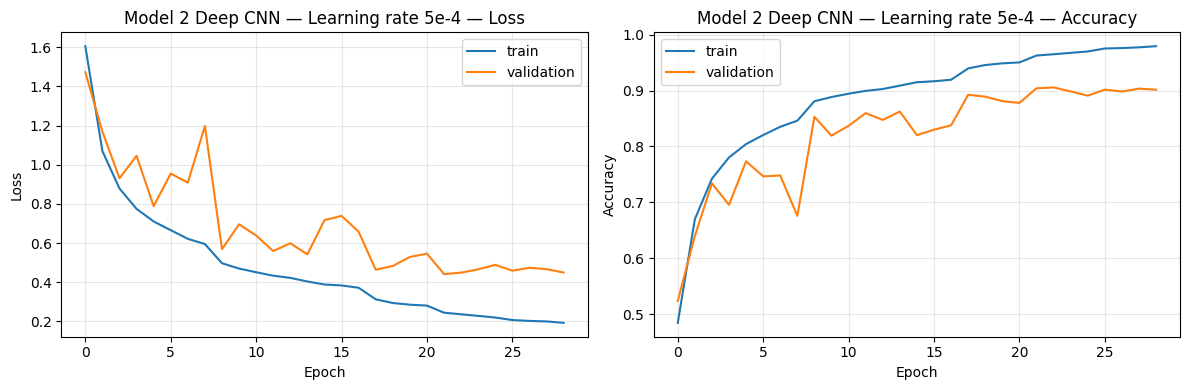

Model 2 — Deep CNN lr=5e-4 | test loss: 0.4717 | test accuracy: 0.8951
              precision    recall  f1-score   support

    airplane      0.917     0.892     0.904      1000
  automobile      0.940     0.962     0.951      1000
        bird      0.840     0.873     0.856      1000
         cat      0.782     0.783     0.783      1000
        deer      0.850     0.925     0.886      1000
         dog      0.893     0.797     0.842      1000
        frog      0.915     0.933     0.924      1000
       horse      0.947     0.909     0.928      1000
        ship      0.939     0.939     0.939      1000
       truck      0.934     0.938     0.936      1000

    accuracy                          0.895     10000
   macro avg      0.896     0.895     0.895     10000
weighted avg      0.896     0.895     0.895     10000

Test accuracy with lr=5e-4: 0.8950999975204468


In [19]:
model_2_lr_5e4 = build_deep_cnn(use_augmentation=True)

history_2_lr_5e4 = train_model(
    model_2_lr_5e4,
    "model_2_deep_cnn_lr_5e4",
    learning_rate=5e-4,
    patience=7
)

plot_history(
    history_2_lr_5e4,
    "Model 2 Deep CNN — Learning rate 5e-4"
)

preds_2_lr_5e4, probs_2_lr_5e4, acc_2_lr_5e4 = evaluate_model(
    model_2_lr_5e4,
    test_ds,
    y_true=y_test,
    model_name="Model 2 — Deep CNN lr=5e-4"
)

print("Test accuracy with lr=5e-4:", acc_2_lr_5e4)


Model: "Deep_CNN_BN_Dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_5 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 32, 32, 3)      │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_28 (Conv2D)              │ (None, 32, 32, 64)     │         1,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_27          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_27 (Activation)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_28          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_28 (Activation)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_30 (Conv2D)              │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_29          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_29 (Activation)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_30          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_30 (Activation)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 8, 8, 256)      │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_31          │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_31 (Activation)      │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 8, 8, 256)      │       589,824 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 2,468,049 (9.41 MB)

 Trainable params: 2,464,202 (9.40 MB)

 Non-trainable params: 3,847 (15.03 KB)

Epoch 1/30


C:\Users\filip\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


352/352 ━━━━━━━━━━━━━━━━━━━━ 170s 471ms/step - accuracy: 0.4907 - loss: 1.5865 - val_accuracy: 0.5102 - val_loss: 1.5951 - learning_rate: 5.0000e-04
Epoch 2/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 176s 499ms/step - accuracy: 0.6733 - loss: 1.0727 - val_accuracy: 0.5348 - val_loss: 1.8739 - learning_rate: 5.0000e-04
Epoch 3/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 169s 479ms/step - accuracy: 0.7433 - loss: 0.8797 - val_accuracy: 0.6530 - val_loss: 1.2371 - learning_rate: 5.0000e-04
Epoch 4/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 169s 480ms/step - accuracy: 0.7777 - loss: 0.7817 - val_accuracy: 0.7554 - val_loss: 0.8455 - learning_rate: 5.0000e-04
Epoch 5/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 169s 479ms/step - accuracy: 0.8034 - loss: 0.7150 - val_accuracy: 0.7312 - val_loss: 0.9423 - learning_rate: 5.0000e-04
Epoch 6/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 168s 476ms/step - accuracy: 0.8210 - loss: 0.6661 - val_accuracy: 0.7014 - val_loss: 1.0675 - learning_rate: 5.0000e-04
Epoch 7/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 171s 486ms/

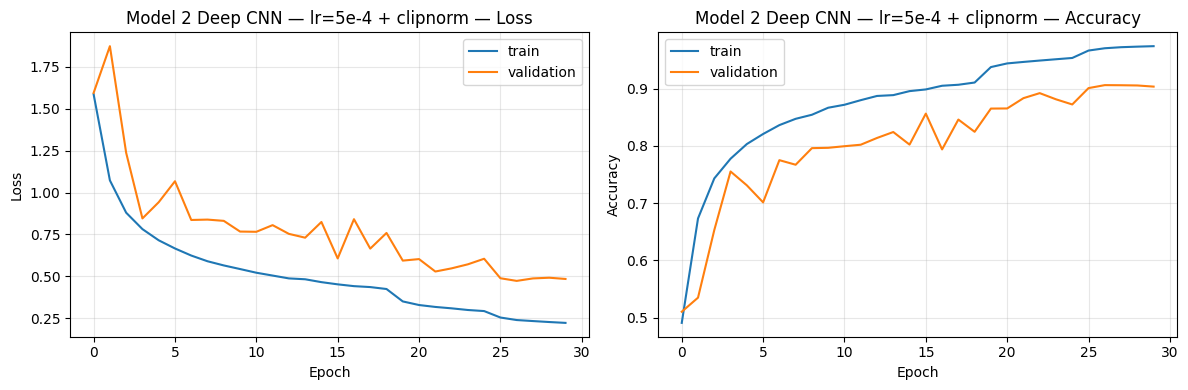

Model 2 — Deep CNN lr=5e-4 + clipnorm | test loss: 0.4878 | test accuracy: 0.8992
              precision    recall  f1-score   support

    airplane      0.937     0.859     0.896      1000
  automobile      0.942     0.964     0.953      1000
        bird      0.868     0.866     0.867      1000
         cat      0.817     0.780     0.798      1000
        deer      0.927     0.897     0.912      1000
         dog      0.783     0.903     0.839      1000
        frog      0.929     0.926     0.927      1000
       horse      0.946     0.915     0.930      1000
        ship      0.947     0.936     0.942      1000
       truck      0.915     0.946     0.930      1000

    accuracy                          0.899     10000
   macro avg      0.901     0.899     0.899     10000
weighted avg      0.901     0.899     0.899     10000

Test accuracy Deep CNN lr=5e-4 + clipnorm: 0.8992000222206116


In [20]:
model_2_clip = build_deep_cnn(use_augmentation=True)

history_2_clip = train_model_clip(
    model_2_clip,
    "model_2_deep_cnn_lr_5e4_clipnorm",
    learning_rate=5e-4,
    patience=7
)

plot_history(
    history_2_clip,
    "Model 2 Deep CNN — lr=5e-4 + clipnorm"
)

preds_2_clip, probs_2_clip, acc_2_clip = evaluate_model(
    model_2_clip,
    test_ds,
    y_true=y_test,
    model_name="Model 2 — Deep CNN lr=5e-4 + clipnorm"
)

print("Test accuracy Deep CNN lr=5e-4 + clipnorm:", acc_2_clip)


Model: "Deep_CNN_L2_2e4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_6 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 32, 32, 3)      │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_36 (Conv2D)              │ (None, 32, 32, 64)     │         1,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_36          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_36 (Activation)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_37 (Conv2D)              │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_37          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_37 (Activation)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_38 (Conv2D)              │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_38          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_38 (Activation)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_39 (Conv2D)              │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_39          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_39 (Activation)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_40 (Conv2D)              │ (None, 8, 8, 256)      │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_40          │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_40 (Activation)      │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_41 (Conv2D)              │ (None, 8, 8, 256)      │       589,824 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 2,468,049 (9.41 MB)

 Trainable params: 2,464,202 (9.40 MB)

 Non-trainable params: 3,847 (15.03 KB)

Epoch 1/30


C:\Users\filip\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


352/352 ━━━━━━━━━━━━━━━━━━━━ 187s 513ms/step - accuracy: 0.4969 - loss: 1.7528 - val_accuracy: 0.5820 - val_loss: 1.5410 - learning_rate: 5.0000e-04
Epoch 2/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 181s 514ms/step - accuracy: 0.6788 - loss: 1.2252 - val_accuracy: 0.6338 - val_loss: 1.4523 - learning_rate: 5.0000e-04
Epoch 3/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 200s 569ms/step - accuracy: 0.7438 - loss: 1.0329 - val_accuracy: 0.6216 - val_loss: 1.4772 - learning_rate: 5.0000e-04
Epoch 4/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 219s 620ms/step - accuracy: 0.7803 - loss: 0.9220 - val_accuracy: 0.6892 - val_loss: 1.2403 - learning_rate: 5.0000e-04
Epoch 5/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 207s 589ms/step - accuracy: 0.8045 - loss: 0.8427 - val_accuracy: 0.6652 - val_loss: 1.3215 - learning_rate: 5.0000e-04
Epoch 6/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 206s 585ms/step - accuracy: 0.8210 - loss: 0.7878 - val_accuracy: 0.7800 - val_loss: 0.8885 - learning_rate: 5.0000e-04
Epoch 7/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 219s 621ms/

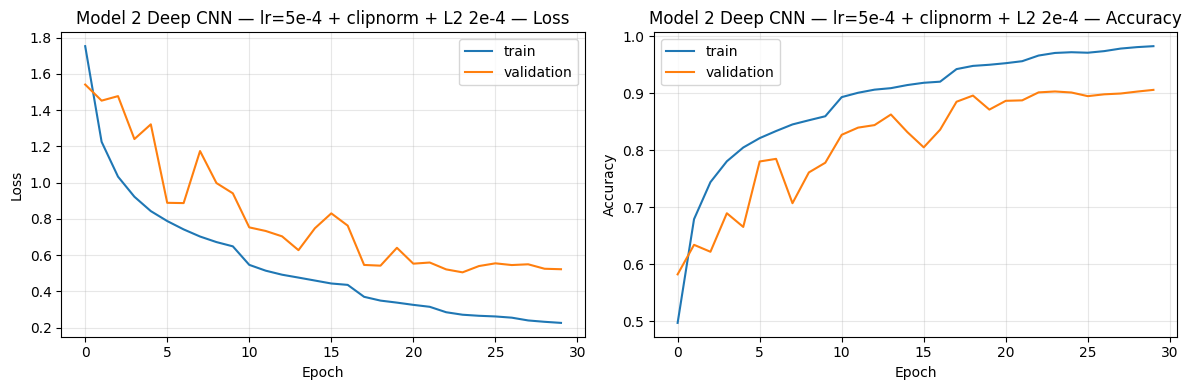

Model 2 — Deep CNN lr=5e-4 + clipnorm + L2 2e-4 | test loss: 0.5351 | test accuracy: 0.8922
              precision    recall  f1-score   support

    airplane      0.941     0.865     0.902      1000
  automobile      0.966     0.951     0.959      1000
        bird      0.878     0.841     0.859      1000
         cat      0.816     0.734     0.773      1000
        deer      0.880     0.908     0.894      1000
         dog      0.845     0.837     0.841      1000
        frog      0.875     0.949     0.910      1000
       horse      0.941     0.923     0.932      1000
        ship      0.848     0.984     0.911      1000
       truck      0.938     0.930     0.934      1000

    accuracy                          0.892     10000
   macro avg      0.893     0.892     0.891     10000
weighted avg      0.893     0.892     0.891     10000

Test accuracy Deep CNN lr=5e-4 + clipnorm + L2 2e-4: 0.8921999931335449


In [21]:
def build_deep_cnn_l2_2e4(use_augmentation=True):
    inputs = keras.Input(shape=(32, 32, 3))

    x = layers.Rescaling(1./255)(inputs)

    if use_augmentation:
        x = augmentation(x)

    x = normalizer(x)

    x = conv_block(x, 64, pool=True, weight_decay=2e-4)
    x = conv_block(x, 128, pool=True, weight_decay=2e-4)
    x = conv_block(x, 256, pool=True, weight_decay=2e-4)
    x = conv_block(x, 256, pool=False, weight_decay=2e-4)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(
        512,
        use_bias=False,
        kernel_regularizer=keras.regularizers.l2(2e-4)
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.50)(x)

    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    return keras.Model(inputs, outputs, name="Deep_CNN_L2_2e4")


model_2_l2_2e4 = build_deep_cnn_l2_2e4(use_augmentation=True)

history_2_l2_2e4 = train_model_clip(
    model_2_l2_2e4,
    "model_2_deep_cnn_lr_5e4_clipnorm_l2_2e4",
    learning_rate=5e-4,
    patience=7
)

plot_history(
    history_2_l2_2e4,
    "Model 2 Deep CNN — lr=5e-4 + clipnorm + L2 2e-4"
)

preds_2_l2_2e4, probs_2_l2_2e4, acc_2_l2_2e4 = evaluate_model(
    model_2_l2_2e4,
    test_ds,
    y_true=y_test,
    model_name="Model 2 — Deep CNN lr=5e-4 + clipnorm + L2 2e-4"
)

print("Test accuracy Deep CNN lr=5e-4 + clipnorm + L2 2e-4:", acc_2_l2_2e4)


Model: "Deep_CNN_Dense_256"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_7 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 32, 32, 3)      │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_44 (Conv2D)              │ (None, 32, 32, 64)     │         1,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_45          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_45 (Activation)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_45 (Conv2D)              │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_46          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_46 (Activation)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_46 (Conv2D)              │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_47          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_47 (Activation)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_47 (Conv2D)              │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_48          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_48 (Activation)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_48 (Conv2D)              │ (None, 8, 8, 256)      │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_49          │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_49 (Activation)      │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_49 (Conv2D)              │ (None, 8, 8, 256)      │       589,824 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 2,398,929 (9.15 MB)

 Trainable params: 2,395,594 (9.14 MB)

 Non-trainable params: 3,335 (13.03 KB)

Epoch 1/30


C:\Users\filip\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


352/352 ━━━━━━━━━━━━━━━━━━━━ 201s 554ms/step - accuracy: 0.4952 - loss: 1.5738 - val_accuracy: 0.4618 - val_loss: 1.7885 - learning_rate: 5.0000e-04
Epoch 2/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 187s 532ms/step - accuracy: 0.6747 - loss: 1.0671 - val_accuracy: 0.5780 - val_loss: 1.5328 - learning_rate: 5.0000e-04
Epoch 3/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 177s 503ms/step - accuracy: 0.7490 - loss: 0.8707 - val_accuracy: 0.5868 - val_loss: 1.5453 - learning_rate: 5.0000e-04
Epoch 4/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 205s 581ms/step - accuracy: 0.7833 - loss: 0.7733 - val_accuracy: 0.7174 - val_loss: 0.9863 - learning_rate: 5.0000e-04
Epoch 5/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 254s 557ms/step - accuracy: 0.8050 - loss: 0.7130 - val_accuracy: 0.7486 - val_loss: 0.8973 - learning_rate: 5.0000e-04
Epoch 6/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 177s 503ms/step - accuracy: 0.8220 - loss: 0.6655 - val_accuracy: 0.7404 - val_loss: 0.9415 - learning_rate: 5.0000e-04
Epoch 7/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 175s 497ms/

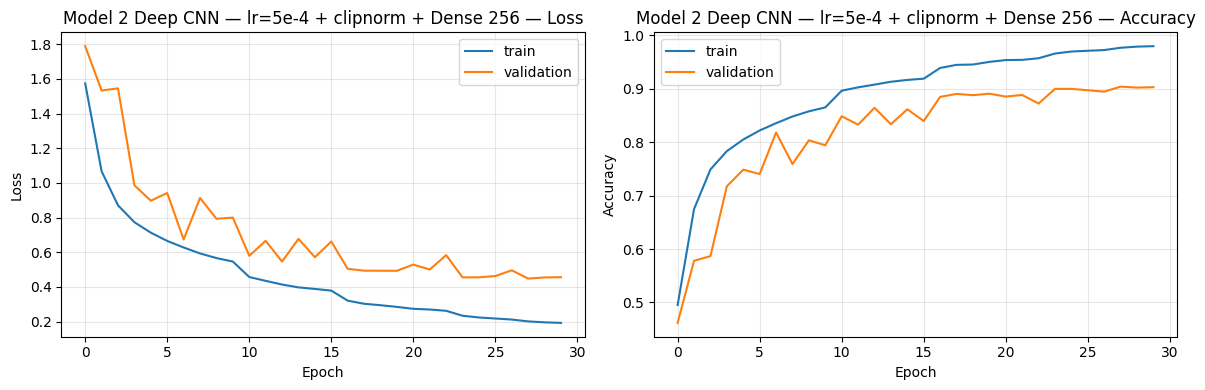

Model 2 — Deep CNN lr=5e-4 + clipnorm + Dense 256 | test loss: 0.4660 | test accuracy: 0.9016
              precision    recall  f1-score   support

    airplane      0.900     0.921     0.911      1000
  automobile      0.946     0.971     0.959      1000
        bird      0.871     0.874     0.872      1000
         cat      0.808     0.786     0.797      1000
        deer      0.912     0.863     0.887      1000
         dog      0.859     0.848     0.854      1000
        frog      0.899     0.936     0.917      1000
       horse      0.938     0.921     0.929      1000
        ship      0.958     0.940     0.949      1000
       truck      0.922     0.956     0.939      1000

    accuracy                          0.902     10000
   macro avg      0.901     0.902     0.901     10000
weighted avg      0.901     0.902     0.901     10000

Test accuracy Deep CNN lr=5e-4 + clipnorm + Dense 256: 0.9016000032424927


In [22]:
def build_deep_cnn_dense_256(use_augmentation=True):
    inputs = keras.Input(shape=(32, 32, 3))

    x = layers.Rescaling(1./255)(inputs)

    if use_augmentation:
        x = augmentation(x)

    x = normalizer(x)

    x = conv_block(x, 64, pool=True, weight_decay=1e-4)
    x = conv_block(x, 128, pool=True, weight_decay=1e-4)
    x = conv_block(x, 256, pool=True, weight_decay=1e-4)
    x = conv_block(x, 256, pool=False, weight_decay=1e-4)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.50)(x)

    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    return keras.Model(inputs, outputs, name="Deep_CNN_Dense_256")


model_2_dense_256 = build_deep_cnn_dense_256(use_augmentation=True)

history_2_dense_256 = train_model_clip(
    model_2_dense_256,
    "model_2_deep_cnn_lr_5e4_clipnorm_dense_256",
    learning_rate=5e-4,
    patience=7
)

plot_history(
    history_2_dense_256,
    "Model 2 Deep CNN — lr=5e-4 + clipnorm + Dense 256"
)

preds_2_dense_256, probs_2_dense_256, acc_2_dense_256 = evaluate_model(
    model_2_dense_256,
    test_ds,
    y_true=y_test,
    model_name="Model 2 — Deep CNN lr=5e-4 + clipnorm + Dense 256"
)

print("Test accuracy Deep CNN lr=5e-4 + clipnorm + Dense 256:", acc_2_dense_256)


## 11. Model 3 — Residual CNN


In [23]:
def residual_block(x, filters, stride=1, weight_decay=1e-4):
    shortcut = x

    x = layers.Conv2D(
        filters,
        3,
        strides=stride,
        padding="same",
        use_bias=False,
        kernel_regularizer=keras.regularizers.l2(weight_decay)
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.Conv2D(
        filters,
        3,
        padding="same",
        use_bias=False,
        kernel_regularizer=keras.regularizers.l2(weight_decay)
    )(x)
    x = layers.BatchNormalization()(x)

    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(
            filters,
            1,
            strides=stride,
            padding="same",
            use_bias=False
        )(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)

    x = layers.Add()([x, shortcut])
    x = layers.Activation("relu")(x)

    return x


def build_res_cnn(use_augmentation=True):
    inputs = keras.Input(shape=(32, 32, 3))

    x = layers.Rescaling(1./255)(inputs)

    if use_augmentation:
        x = augmentation(x)

    x = normalizer(x)

    x = layers.Conv2D(64, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = residual_block(x, 64)
    x = residual_block(x, 64)

    x = residual_block(x, 128, stride=2)
    x = residual_block(x, 128)

    x = residual_block(x, 256, stride=2)   
    x = residual_block(x, 256)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.40)(x)

    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    return keras.Model(inputs, outputs, name="Residual_CNN")


Model: "Residual_CNN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_9       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_8         │ (None, 32, 32, 3) │          0 │ input_layer_9[0]… │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 32, 32, 3) │          0 │ rescaling_8[0][0] │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 32, 32, 3) │          7 │ data_augmentatio… │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_52 (Conv2D)  │ (None, 32, 32,    │      1,728 │ normalization[8]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_52[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_54       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_53 (Conv2D)  │ (None, 32, 32,    │     36,864 │ activation_54[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_53[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_55       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_54 (Conv2D)  │ (None, 32, 32,    │     36,864 │ activation_55[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_54[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │ activation_54[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_56       │ (None, 32, 32,    │          0 │ add[0][0]         │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_55 (Conv2D)  │ (None, 32, 32,    │     36,864 │ activation_56[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_55[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_57       │ (None, 32, 32,    │          0 │ batch_normalizat

 Total params: 2,782,161 (10.61 MB)

 Trainable params: 2,777,674 (10.60 MB)

 Non-trainable params: 4,487 (17.53 KB)

Epoch 1/30


C:\Users\filip\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


352/352 ━━━━━━━━━━━━━━━━━━━━ 406s 1s/step - accuracy: 0.4449 - loss: 1.7316 - val_accuracy: 0.4104 - val_loss: 2.0030 - learning_rate: 0.0010
Epoch 2/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 401s 1s/step - accuracy: 0.6220 - loss: 1.2337 - val_accuracy: 0.5976 - val_loss: 1.3031 - learning_rate: 0.0010
Epoch 3/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 401s 1s/step - accuracy: 0.7076 - loss: 1.0091 - val_accuracy: 0.6590 - val_loss: 1.1136 - learning_rate: 0.0010
Epoch 4/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 401s 1s/step - accuracy: 0.7571 - loss: 0.8794 - val_accuracy: 0.6800 - val_loss: 1.1565 - learning_rate: 0.0010
Epoch 5/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 418s 1s/step - accuracy: 0.7833 - loss: 0.8075 - val_accuracy: 0.7078 - val_loss: 1.1183 - learning_rate: 0.0010
Epoch 6/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 433s 1s/step - accuracy: 0.8057 - loss: 0.7514 - val_accuracy: 0.7386 - val_loss: 0.9729 - learning_rate: 0.0010
Epoch 7/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 427s 1s/step - accuracy: 0.8218 - loss: 0.7134 - val_

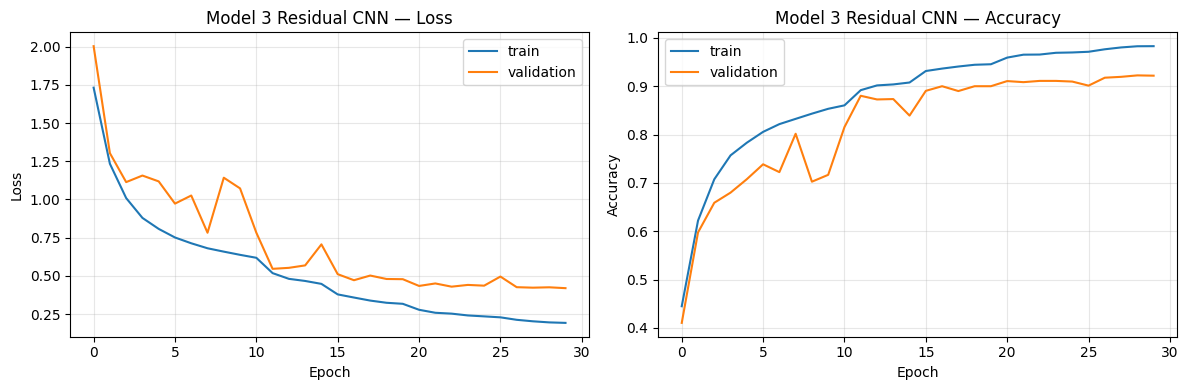

Model 3 — Residual CNN | test loss: 0.4201 | test accuracy: 0.9162
              precision    recall  f1-score   support

    airplane      0.933     0.921     0.927      1000
  automobile      0.942     0.978     0.960      1000
        bird      0.887     0.867     0.877      1000
         cat      0.840     0.834     0.837      1000
        deer      0.916     0.916     0.916      1000
         dog      0.864     0.869     0.866      1000
        frog      0.920     0.943     0.931      1000
       horse      0.968     0.937     0.952      1000
        ship      0.946     0.956     0.951      1000
       truck      0.946     0.941     0.943      1000

    accuracy                          0.916     10000
   macro avg      0.916     0.916     0.916     10000
weighted avg      0.916     0.916     0.916     10000



In [24]:
model_3 = build_res_cnn(use_augmentation=True)

history_3 = train_model(
    model_3,
    "model_3_res_cnn",
    patience=7
)

plot_history(
    history_3,
    "Model 3 Residual CNN"
)

preds_3, probs_3, acc_3 = evaluate_model(
    model_3,
    test_ds,
    y_true=y_test,
    model_name="Model 3 — Residual CNN"
)


## 12. Model 3 experiments — Clipping and stronger augmentation


Model: "Residual_CNN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_10      │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_9         │ (None, 32, 32, 3) │          0 │ input_layer_10[0… │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 32, 32, 3) │          0 │ rescaling_9[0][0] │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 32, 32, 3) │          7 │ data_augmentatio… │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_67 (Conv2D)  │ (None, 32, 32,    │      1,728 │ normalization[9]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_67[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_67       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_68 (Conv2D)  │ (None, 32, 32,    │     36,864 │ activation_67[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_68[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_68       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_69 (Conv2D)  │ (None, 32, 32,    │     36,864 │ activation_68[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_69[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_6 (Add)         │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │ activation_67[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_69       │ (None, 32, 32,    │          0 │ add_6[0][0]       │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_70 (Conv2D)  │ (None, 32, 32,    │     36,864 │ activation_69[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_70[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_70       │ (None, 32, 32,    │          0 │ batch_normalizat

 Total params: 2,782,161 (10.61 MB)

 Trainable params: 2,777,674 (10.60 MB)

 Non-trainable params: 4,487 (17.53 KB)

Epoch 1/30


C:\Users\filip\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


352/352 ━━━━━━━━━━━━━━━━━━━━ 425s 1s/step - accuracy: 0.4434 - loss: 1.7248 - val_accuracy: 0.5480 - val_loss: 1.4235 - learning_rate: 5.0000e-04
Epoch 2/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 432s 1s/step - accuracy: 0.6202 - loss: 1.2383 - val_accuracy: 0.5050 - val_loss: 1.6473 - learning_rate: 5.0000e-04
Epoch 3/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 418s 1s/step - accuracy: 0.7066 - loss: 1.0085 - val_accuracy: 0.6486 - val_loss: 1.2536 - learning_rate: 5.0000e-04
Epoch 4/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 417s 1s/step - accuracy: 0.7548 - loss: 0.8764 - val_accuracy: 0.7184 - val_loss: 1.0330 - learning_rate: 5.0000e-04
Epoch 5/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 411s 1s/step - accuracy: 0.7835 - loss: 0.7877 - val_accuracy: 0.7238 - val_loss: 0.9844 - learning_rate: 5.0000e-04
Epoch 6/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 426s 1s/step - accuracy: 0.8062 - loss: 0.7276 - val_accuracy: 0.7606 - val_loss: 0.8360 - learning_rate: 5.0000e-04
Epoch 7/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 466s 1s/step - accuracy: 0.82

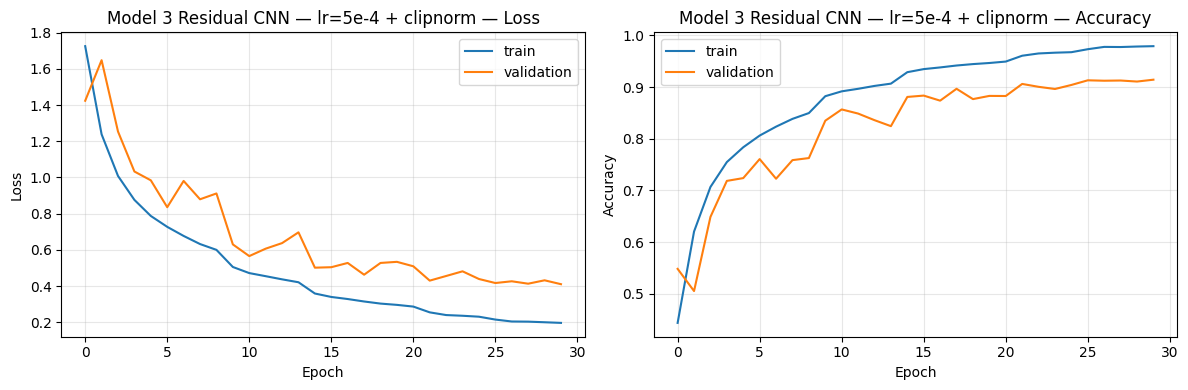

Model 3 — Residual CNN lr=5e-4 + clipnorm | test loss: 0.4187 | test accuracy: 0.9125
              precision    recall  f1-score   support

    airplane      0.926     0.919     0.923      1000
  automobile      0.960     0.962     0.961      1000
        bird      0.932     0.847     0.887      1000
         cat      0.779     0.838     0.807      1000
        deer      0.931     0.913     0.922      1000
         dog      0.888     0.850     0.869      1000
        frog      0.906     0.939     0.922      1000
       horse      0.941     0.948     0.945      1000
        ship      0.943     0.956     0.949      1000
       truck      0.929     0.953     0.941      1000

    accuracy                          0.912     10000
   macro avg      0.914     0.912     0.913     10000
weighted avg      0.914     0.912     0.913     10000

Test accuracy Residual CNN lr=5e-4 + clipnorm: 0.9125000238418579


In [25]:
model_3_clip = build_res_cnn(use_augmentation=True)

history_3_clip = train_model_clip(
    model_3_clip,
    "model_3_res_cnn_lr_5e4_clipnorm",
    learning_rate=5e-4,
    patience=7
)

plot_history(
    history_3_clip,
    "Model 3 Residual CNN — lr=5e-4 + clipnorm"
)

preds_3_clip, probs_3_clip, acc_3_clip = evaluate_model(
    model_3_clip,
    test_ds,
    y_true=y_test,
    model_name="Model 3 — Residual CNN lr=5e-4 + clipnorm"
)

print("Test accuracy Residual CNN lr=5e-4 + clipnorm:", acc_3_clip)


Model: "Residual_CNN_Stronger_Aug"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_11      │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_10        │ (None, 32, 32, 3) │          0 │ input_layer_11[0… │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation_… │ (None, 32, 32, 3) │          0 │ rescaling_10[0][… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 32, 32, 3) │          7 │ data_augmentatio… │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_82 (Conv2D)  │ (None, 32, 32,    │      1,728 │ normalization[10… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_82[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_80       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_83 (Conv2D)  │ (None, 32, 32,    │     36,864 │ activation_80[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_83[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_81       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_84 (Conv2D)  │ (None, 32, 32,    │     36,864 │ activation_81[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_84[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_12 (Add)        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │ activation_80[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_82       │ (None, 32, 32,    │          0 │ add_12[0][0]      │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_85 (Conv2D)  │ (None, 32, 32,    │     36,864 │ activation_82[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_85[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_83       │ (None, 32, 32,    │          0 │ batch_normalizat

 Total params: 2,782,161 (10.61 MB)

 Trainable params: 2,777,674 (10.60 MB)

 Non-trainable params: 4,487 (17.53 KB)

Epoch 1/30


C:\Users\filip\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


352/352 ━━━━━━━━━━━━━━━━━━━━ 373s 1s/step - accuracy: 0.4406 - loss: 1.7451 - val_accuracy: 0.5506 - val_loss: 1.3908 - learning_rate: 5.0000e-04
Epoch 2/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 364s 1s/step - accuracy: 0.6100 - loss: 1.2650 - val_accuracy: 0.6090 - val_loss: 1.3573 - learning_rate: 5.0000e-04
Epoch 3/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 367s 1s/step - accuracy: 0.6906 - loss: 1.0491 - val_accuracy: 0.6738 - val_loss: 1.0953 - learning_rate: 5.0000e-04
Epoch 4/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 364s 1s/step - accuracy: 0.7396 - loss: 0.9181 - val_accuracy: 0.7120 - val_loss: 0.9883 - learning_rate: 5.0000e-04
Epoch 5/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 364s 1s/step - accuracy: 0.7692 - loss: 0.8350 - val_accuracy: 0.7296 - val_loss: 0.9672 - learning_rate: 5.0000e-04
Epoch 6/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 363s 1s/step - accuracy: 0.7956 - loss: 0.7632 - val_accuracy: 0.7664 - val_loss: 0.8416 - learning_rate: 5.0000e-04
Epoch 7/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 364s 1s/step - accuracy: 0.80

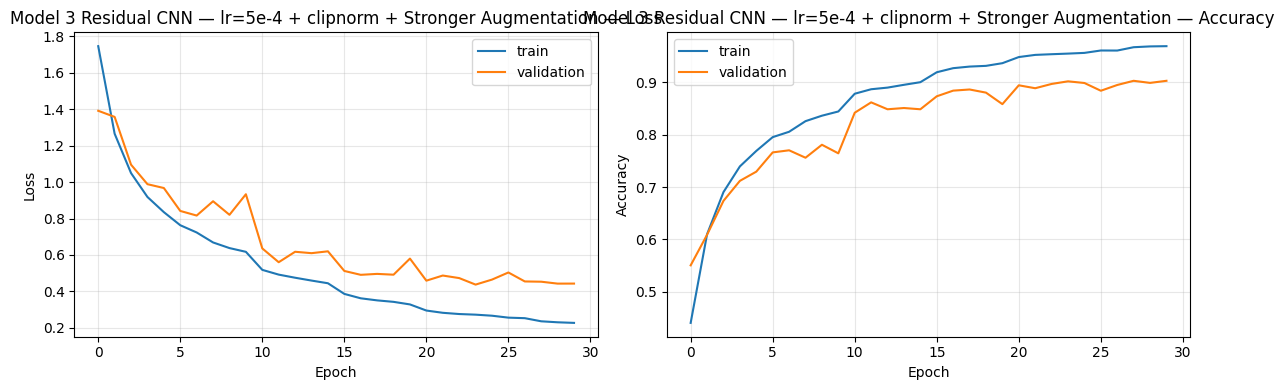

Model 3 — Residual CNN lr=5e-4 + clipnorm + Stronger Augmentation | test loss: 0.4528 | test accuracy: 0.9024
              precision    recall  f1-score   support

    airplane      0.920     0.904     0.912      1000
  automobile      0.951     0.962     0.956      1000
        bird      0.801     0.893     0.844      1000
         cat      0.877     0.753     0.810      1000
        deer      0.891     0.917     0.904      1000
         dog      0.876     0.813     0.843      1000
        frog      0.903     0.946     0.924      1000
       horse      0.925     0.941     0.933      1000
        ship      0.928     0.957     0.942      1000
       truck      0.959     0.938     0.948      1000

    accuracy                          0.902     10000
   macro avg      0.903     0.902     0.902     10000
weighted avg      0.903     0.902     0.902     10000

Test accuracy Residual CNN stronger augmentation: 0.902400016784668


In [26]:
augmentation_stronger = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(height_factor=0.12, width_factor=0.12, fill_mode="reflect"),
    layers.RandomZoom(height_factor=0.08, width_factor=0.08, fill_mode="reflect"),
    layers.RandomContrast(0.15),
], name="data_augmentation_stronger")


def build_res_cnn_stronger_aug(use_augmentation=True):
    inputs = keras.Input(shape=(32, 32, 3))

    x = layers.Rescaling(1./255)(inputs)

    if use_augmentation:
        x = augmentation_stronger(x)

    x = normalizer(x)

    x = layers.Conv2D(64, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = residual_block(x, 64)
    x = residual_block(x, 64)

    x = residual_block(x, 128, stride=2)
    x = residual_block(x, 128)

    x = residual_block(x, 256, stride=2)
    x = residual_block(x, 256)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.40)(x)

    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    return keras.Model(inputs, outputs, name="Residual_CNN_Stronger_Aug")


model_3_stronger_aug = build_res_cnn_stronger_aug(use_augmentation=True)

history_3_stronger_aug = train_model_clip(
    model_3_stronger_aug,
    "model_3_res_cnn_lr_5e4_clipnorm_stronger_aug",
    train_ds=train_ds,
    val_ds=val_ds,
    epochs=EPOCHS,
    learning_rate=5e-4,
    patience=7
)

plot_history(
    history_3_stronger_aug,
    "Model 3 Residual CNN — lr=5e-4 + clipnorm + Stronger Augmentation"
)

preds_3_stronger_aug, probs_3_stronger_aug, acc_3_stronger_aug = evaluate_model(
    model_3_stronger_aug,
    test_ds,
    y_true=y_test,
    model_name="Model 3 — Residual CNN lr=5e-4 + clipnorm + Stronger Augmentation"
)

print("Test accuracy Residual CNN stronger augmentation:", acc_3_stronger_aug)


## 13. Transfer learning datasets


In [27]:
def preprocess_for_mobilenet(x, y, training=False):
    x = tf.cast(x, tf.float32)
    x = tf.image.resize(x, (TL_IMG_SIZE, TL_IMG_SIZE))

    if training:
        x = tf.image.random_flip_left_right(x, seed=SEED)

    x = keras.applications.mobilenet_v2.preprocess_input(x)
    return x, y


def make_tl_dataset(x, y, training=False, batch_size=BATCH_SIZE):
    ds = tf.data.Dataset.from_tensor_slices((x, y))

    if training:
        ds = ds.shuffle(len(x), seed=SEED, reshuffle_each_iteration=True)

    ds = ds.map(
        lambda a, b: preprocess_for_mobilenet(a, b, training=training),
        num_parallel_calls=tf.data.AUTOTUNE
    )
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

    return ds


tl_train_ds = make_tl_dataset(x_train, y_train, training=True)
tl_val_ds = make_tl_dataset(x_val, y_val, training=False)
tl_test_ds = make_tl_dataset(x_test, y_test, training=False)

print(tl_train_ds)


<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 96, 96, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>


## 14. Model 4 — MobileNetV2 transfer learning


In [28]:
def build_mobilenet_transfer(freeze_backbone=True):
    base_model = keras.applications.MobileNetV2(
        input_shape=(TL_IMG_SIZE, TL_IMG_SIZE, 3),
        include_top=False,
        weights="imagenet",
        pooling="avg"
    )
    base_model.trainable = not freeze_backbone

    inputs = keras.Input(shape=(TL_IMG_SIZE, TL_IMG_SIZE, 3))

    x = base_model(inputs, training=False)
    x = layers.Dropout(0.30)(x)
    x = layers.Dense(512, activation="relu")(x)
    x = layers.Dropout(0.40)(x)

    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    return keras.Model(inputs, outputs, name="MobileNetV2_transfer")


Model: "MobileNetV2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_14 (InputLayer)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 1280)           │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 512)            │       655,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,918,986 (11.14 MB)

 Trainable params: 661,002 (2.52 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/30


C:\Users\filip\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


352/352 ━━━━━━━━━━━━━━━━━━━━ 85s 232ms/step - accuracy: 0.7758 - loss: 0.6694 - val_accuracy: 0.8418 - val_loss: 0.4491 - learning_rate: 0.0010
Epoch 2/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 82s 234ms/step - accuracy: 0.8272 - loss: 0.5017 - val_accuracy: 0.8616 - val_loss: 0.3995 - learning_rate: 0.0010
Epoch 3/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 81s 231ms/step - accuracy: 0.8430 - loss: 0.4570 - val_accuracy: 0.8658 - val_loss: 0.3796 - learning_rate: 0.0010
Epoch 4/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 80s 228ms/step - accuracy: 0.8521 - loss: 0.4263 - val_accuracy: 0.8708 - val_loss: 0.3628 - learning_rate: 0.0010
Epoch 5/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 80s 226ms/step - accuracy: 0.8581 - loss: 0.4059 - val_accuracy: 0.8708 - val_loss: 0.3657 - learning_rate: 0.0010
Epoch 6/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 81s 230ms/step - accuracy: 0.8658 - loss: 0.3855 - val_accuracy: 0.8726 - val_loss: 0.3559 - learning_rate: 0.0010
Epoch 7/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 80s 227ms/step - accuracy: 0.8682 - loss:

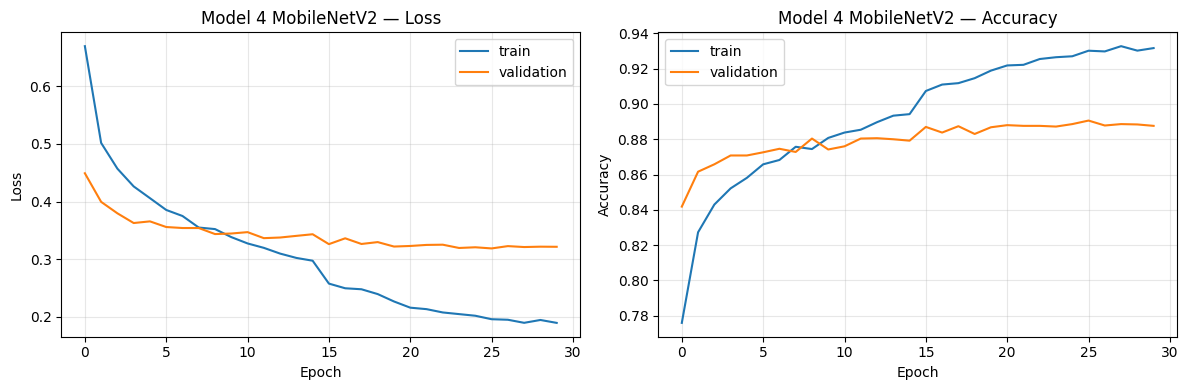

Model 4 — MobileNetV2 Transfer | test loss: 0.3412 | test accuracy: 0.8844
              precision    recall  f1-score   support

    airplane      0.884     0.900     0.892      1000
  automobile      0.937     0.938     0.938      1000
        bird      0.898     0.860     0.878      1000
         cat      0.768     0.780     0.774      1000
        deer      0.844     0.879     0.861      1000
         dog      0.852     0.820     0.835      1000
        frog      0.895     0.917     0.906      1000
       horse      0.914     0.889     0.901      1000
        ship      0.927     0.938     0.932      1000
       truck      0.929     0.923     0.926      1000

    accuracy                          0.884     10000
   macro avg      0.885     0.884     0.884     10000
weighted avg      0.885     0.884     0.884     10000



In [29]:
model_4 = build_mobilenet_transfer(freeze_backbone=True)

history_4 = train_model(
    model_4,
    "model_4_mobilenetv2_transfer",
    train_ds=tl_train_ds,
    val_ds=tl_val_ds,
    epochs=EPOCHS,
    learning_rate=1e-3,
    patience=6
)

plot_history(
    history_4,
    "Model 4 MobileNetV2"
)

preds_4, probs_4, acc_4 = evaluate_model(
    model_4,
    tl_test_ds,
    y_true=y_test,
    model_name="Model 4 — MobileNetV2 Transfer"
)


## 15. Model 4 — MobileNetV2 fine-tuning


Epoch 1/10


C:\Users\filip\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


352/352 ━━━━━━━━━━━━━━━━━━━━ 107s 288ms/step - accuracy: 0.8033 - loss: 0.8866 - val_accuracy: 0.8752 - val_loss: 0.3972 - learning_rate: 1.0000e-05
Epoch 2/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 101s 287ms/step - accuracy: 0.8488 - loss: 0.5848 - val_accuracy: 0.8774 - val_loss: 0.3907 - learning_rate: 1.0000e-05
Epoch 3/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 106s 300ms/step - accuracy: 0.8644 - loss: 0.4868 - val_accuracy: 0.8818 - val_loss: 0.3826 - learning_rate: 1.0000e-05
Epoch 4/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 100s 284ms/step - accuracy: 0.8749 - loss: 0.4151 - val_accuracy: 0.8814 - val_loss: 0.3774 - learning_rate: 1.0000e-05
Epoch 5/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 100s 284ms/step - accuracy: 0.8849 - loss: 0.3732 - val_accuracy: 0.8846 - val_loss: 0.3696 - learning_rate: 1.0000e-05
Epoch 6/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 100s 284ms/step - accuracy: 0.8929 - loss: 0.3397 - val_accuracy: 0.8838 - val_loss: 0.3631 - learning_rate: 1.0000e-05
Epoch 7/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 100s 285ms/

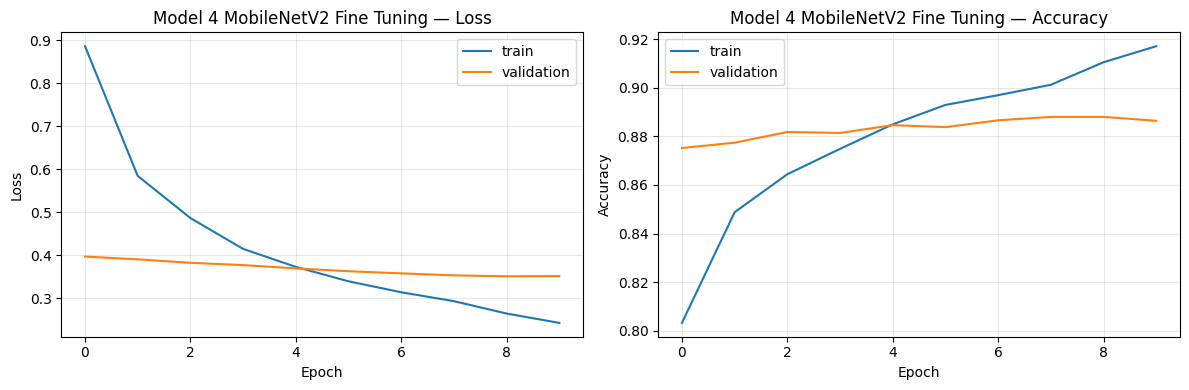

Model 4 — MobileNetV2 Fine-tuned | test loss: 0.3650 | test accuracy: 0.8902
              precision    recall  f1-score   support

    airplane      0.879     0.908     0.893      1000
  automobile      0.953     0.940     0.947      1000
        bird      0.882     0.868     0.875      1000
         cat      0.792     0.805     0.799      1000
        deer      0.860     0.869     0.864      1000
         dog      0.857     0.826     0.841      1000
        frog      0.902     0.922     0.912      1000
       horse      0.922     0.907     0.914      1000
        ship      0.922     0.928     0.925      1000
       truck      0.935     0.929     0.932      1000

    accuracy                          0.890     10000
   macro avg      0.890     0.890     0.890     10000
weighted avg      0.890     0.890     0.890     10000



In [30]:
base_model = model_4.get_layer(index=1)
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

compile_model(model_4, learning_rate=1e-5)

history_4_ft = model_4.fit(
    tl_train_ds,
    validation_data=tl_val_ds,
    epochs=10,
    callbacks=get_callbacks("model_4_mobilenetv2_finetuned", patience=4),
    verbose=1
)

plot_history(
    history_4_ft,
    "Model 4 MobileNetV2 Fine Tuning"
)

preds_4_ft, probs_4_ft, acc_4_ft = evaluate_model(
    model_4,
    tl_test_ds,
    y_true=y_test,
    model_name="Model 4 — MobileNetV2 Fine-tuned"
)


## 16. Model 4 — MobileNetV2 with stronger augmentation


Model: "MobileNetV2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_16 (InputLayer)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 1280)           │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 512)            │       655,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,918,986 (11.14 MB)

 Trainable params: 661,002 (2.52 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/30


C:\Users\filip\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


352/352 ━━━━━━━━━━━━━━━━━━━━ 86s 233ms/step - accuracy: 0.7404 - loss: 0.7680 - val_accuracy: 0.8356 - val_loss: 0.4631 - learning_rate: 0.0010
Epoch 2/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 81s 229ms/step - accuracy: 0.7943 - loss: 0.5946 - val_accuracy: 0.8592 - val_loss: 0.4001 - learning_rate: 0.0010
Epoch 3/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 82s 234ms/step - accuracy: 0.8097 - loss: 0.5493 - val_accuracy: 0.8578 - val_loss: 0.3959 - learning_rate: 0.0010
Epoch 4/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 83s 235ms/step - accuracy: 0.8156 - loss: 0.5273 - val_accuracy: 0.8662 - val_loss: 0.3772 - learning_rate: 0.0010
Epoch 5/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 81s 229ms/step - accuracy: 0.8224 - loss: 0.5082 - val_accuracy: 0.8694 - val_loss: 0.3744 - learning_rate: 0.0010
Epoch 6/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 81s 229ms/step - accuracy: 0.8290 - loss: 0.4917 - val_accuracy: 0.8644 - val_loss: 0.3830 - learning_rate: 0.0010
Epoch 7/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 81s 231ms/step - accuracy: 0.8333 - loss:

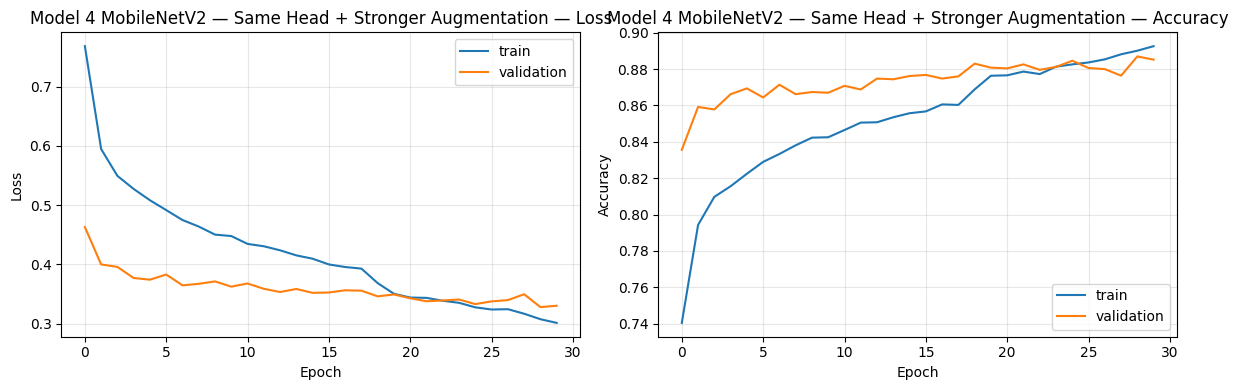

Model 4 — MobileNetV2 Same Head + Stronger Augmentation | test loss: 0.3486 | test accuracy: 0.8830
              precision    recall  f1-score   support

    airplane      0.891     0.903     0.897      1000
  automobile      0.939     0.942     0.941      1000
        bird      0.913     0.842     0.876      1000
         cat      0.807     0.736     0.770      1000
        deer      0.835     0.868     0.851      1000
         dog      0.855     0.817     0.835      1000
        frog      0.890     0.929     0.909      1000
       horse      0.877     0.918     0.897      1000
        ship      0.904     0.951     0.927      1000
       truck      0.914     0.924     0.919      1000

    accuracy                          0.883     10000
   macro avg      0.882     0.883     0.882     10000
weighted avg      0.882     0.883     0.882     10000

Test accuracy MobileNetV2 same head + stronger augmentation: 0.8830000162124634


In [31]:
def preprocess_for_mobilenet_aug(x, y, training=False):
    x = tf.cast(x, tf.float32)

    if training:
        x = tf.image.resize(x, (TL_IMG_SIZE + 8, TL_IMG_SIZE + 8))
        x = tf.image.random_crop(x, size=(TL_IMG_SIZE, TL_IMG_SIZE, 3), seed=SEED)
        x = tf.image.random_flip_left_right(x, seed=SEED)
        x = tf.image.random_brightness(x, max_delta=0.05)
        x = tf.image.random_contrast(x, lower=0.90, upper=1.10)
    else:
        x = tf.image.resize(x, (TL_IMG_SIZE, TL_IMG_SIZE))

    x = keras.applications.mobilenet_v2.preprocess_input(x)

    return x, y


def make_tl_dataset_aug(x, y, training=False, batch_size=BATCH_SIZE):
    ds = tf.data.Dataset.from_tensor_slices((x, y))

    if training:
        ds = ds.shuffle(len(x), seed=SEED, reshuffle_each_iteration=True)

    ds = ds.map(
        lambda a, b: preprocess_for_mobilenet_aug(a, b, training=training),
        num_parallel_calls=tf.data.AUTOTUNE
    )
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

    return ds


tl_train_ds_aug = make_tl_dataset_aug(x_train, y_train, training=True)
tl_val_ds_aug = make_tl_dataset_aug(x_val, y_val, training=False)
tl_test_ds_aug = make_tl_dataset_aug(x_test, y_test, training=False)


model_4_aug = build_mobilenet_transfer(freeze_backbone=True)

history_4_aug = train_model(
    model_4_aug,
    "model_4_mobilenetv2_same_head_aug",
    train_ds=tl_train_ds_aug,
    val_ds=tl_val_ds_aug,
    epochs=EPOCHS,
    learning_rate=1e-3,
    patience=6
)

plot_history(
    history_4_aug,
    "Model 4 MobileNetV2 — Same Head + Stronger Augmentation"
)

preds_4_aug, probs_4_aug, acc_4_aug = evaluate_model(
    model_4_aug,
    tl_test_ds_aug,
    y_true=y_test,
    model_name="Model 4 — MobileNetV2 Same Head + Stronger Augmentation"
)

print("Test accuracy MobileNetV2 same head + stronger augmentation:", acc_4_aug)


## 17. Model 4 — MobileNetV2 stronger augmentation + fine-tuning


Epoch 1/20


C:\Users\filip\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


352/352 ━━━━━━━━━━━━━━━━━━━━ 95s 259ms/step - accuracy: 0.8949 - loss: 0.2966 - val_accuracy: 0.8870 - val_loss: 0.3390 - learning_rate: 1.0000e-05
Epoch 2/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 90s 256ms/step - accuracy: 0.9002 - loss: 0.2801 - val_accuracy: 0.8924 - val_loss: 0.3223 - learning_rate: 1.0000e-05
Epoch 3/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 90s 256ms/step - accuracy: 0.9060 - loss: 0.2641 - val_accuracy: 0.8888 - val_loss: 0.3297 - learning_rate: 1.0000e-05
Epoch 4/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 90s 255ms/step - accuracy: 0.9104 - loss: 0.2550 - val_accuracy: 0.8922 - val_loss: 0.3194 - learning_rate: 1.0000e-05
Epoch 5/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 90s 256ms/step - accuracy: 0.9121 - loss: 0.2471 - val_accuracy: 0.8960 - val_loss: 0.3191 - learning_rate: 1.0000e-05
Epoch 6/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 90s 256ms/step - accuracy: 0.9153 - loss: 0.2430 - val_accuracy: 0.8936 - val_loss: 0.3178 - learning_rate: 1.0000e-05
Epoch 7/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 90s 255ms/step - 

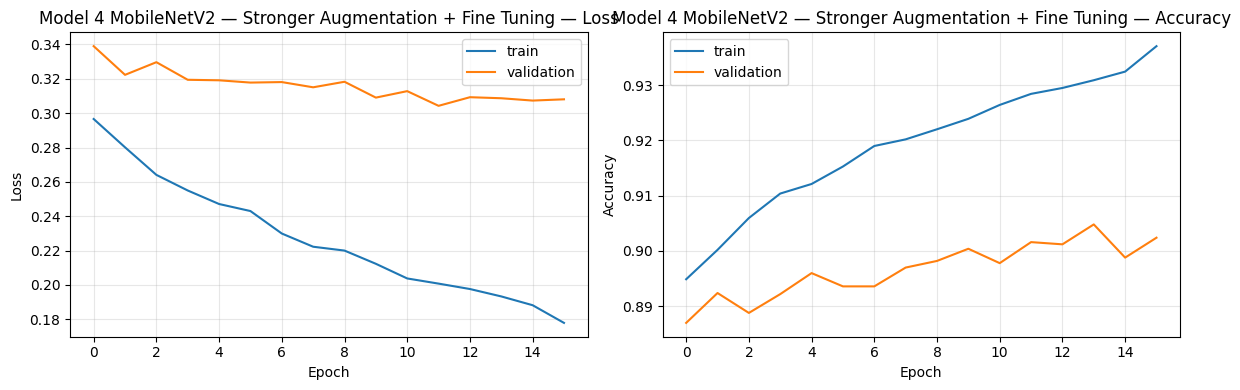

Model 4 — MobileNetV2 Stronger Augmentation + Fine-tuned | test loss: 0.3202 | test accuracy: 0.8981
              precision    recall  f1-score   support

    airplane      0.909     0.914     0.911      1000
  automobile      0.939     0.958     0.949      1000
        bird      0.924     0.871     0.897      1000
         cat      0.856     0.737     0.792      1000
        deer      0.847     0.881     0.864      1000
         dog      0.850     0.856     0.853      1000
        frog      0.897     0.944     0.920      1000
       horse      0.902     0.944     0.922      1000
        ship      0.914     0.956     0.935      1000
       truck      0.941     0.920     0.930      1000

    accuracy                          0.898     10000
   macro avg      0.898     0.898     0.897     10000
weighted avg      0.898     0.898     0.897     10000

Test accuracy MobileNetV2 stronger augmentation + fine-tuned: 0.8981000185012817


In [32]:
base_model = model_4_aug.layers[1]
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model_4_aug.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-5,
        clipnorm=1.0
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_4_aug_ft = model_4_aug.fit(
    tl_train_ds_aug,
    validation_data=tl_val_ds_aug,
    epochs=20,
    callbacks=get_callbacks("model_4_mobilenetv2_aug_finetuned", patience=4),
    verbose=1
)

plot_history(
    history_4_aug_ft,
    "Model 4 MobileNetV2 — Stronger Augmentation + Fine Tuning"
)

preds_4_aug_ft, probs_4_aug_ft, acc_4_aug_ft = evaluate_model(
    model_4_aug,
    tl_test_ds_aug,
    y_true=y_test,
    model_name="Model 4 — MobileNetV2 Stronger Augmentation + Fine-tuned"
)

print("Test accuracy MobileNetV2 stronger augmentation + fine-tuned:", acc_4_aug_ft)


## 18. Model 5 — ResNet50 transfer learning


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 11s 0us/step


Model: "ResNet50_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_18 (InputLayer)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 2048)           │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,641,930 (94.00 MB)

 Trainable params: 1,054,218 (4.02 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

Epoch 1/30


C:\Users\filip\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


352/352 ━━━━━━━━━━━━━━━━━━━━ 225s 626ms/step - accuracy: 0.7834 - loss: 0.6814 - val_accuracy: 0.8460 - val_loss: 0.4434 - learning_rate: 5.0000e-04
Epoch 2/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 220s 626ms/step - accuracy: 0.8455 - loss: 0.4492 - val_accuracy: 0.8634 - val_loss: 0.3959 - learning_rate: 5.0000e-04
Epoch 3/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 217s 618ms/step - accuracy: 0.8645 - loss: 0.3941 - val_accuracy: 0.8708 - val_loss: 0.3823 - learning_rate: 5.0000e-04
Epoch 4/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 218s 619ms/step - accuracy: 0.8767 - loss: 0.3555 - val_accuracy: 0.8724 - val_loss: 0.3716 - learning_rate: 5.0000e-04
Epoch 5/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 217s 617ms/step - accuracy: 0.8886 - loss: 0.3209 - val_accuracy: 0.8762 - val_loss: 0.3646 - learning_rate: 5.0000e-04
Epoch 6/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 217s 616ms/step - accuracy: 0.8952 - loss: 0.2991 - val_accuracy: 0.8758 - val_loss: 0.3744 - learning_rate: 5.0000e-04
Epoch 7/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 218s 620ms/

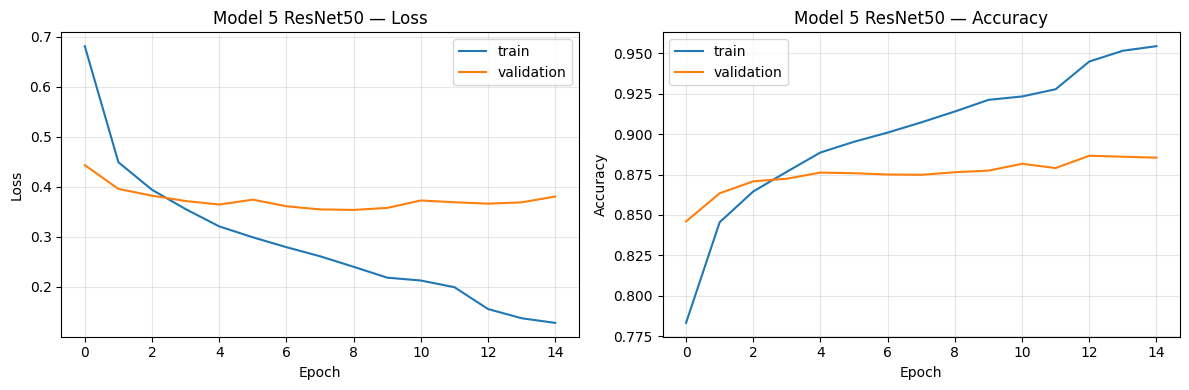

Model 5 — ResNet50 Transfer | test loss: 0.3705 | test accuracy: 0.8770
              precision    recall  f1-score   support

    airplane      0.911     0.885     0.898      1000
  automobile      0.929     0.906     0.917      1000
        bird      0.845     0.892     0.868      1000
         cat      0.808     0.751     0.778      1000
        deer      0.855     0.851     0.853      1000
         dog      0.816     0.832     0.824      1000
        frog      0.896     0.900     0.898      1000
       horse      0.899     0.895     0.897      1000
        ship      0.930     0.930     0.930      1000
       truck      0.880     0.928     0.904      1000

    accuracy                          0.877     10000
   macro avg      0.877     0.877     0.877     10000
weighted avg      0.877     0.877     0.877     10000



In [33]:
def preprocess_for_resnet50(x, y, training=False):
    x = tf.cast(x, tf.float32)
    x = tf.image.resize(x, (TL_IMG_SIZE, TL_IMG_SIZE))

    if training:
        x = tf.image.random_flip_left_right(x, seed=SEED)

    x = keras.applications.resnet50.preprocess_input(x)

    return x, y


def make_resnet50_dataset(x, y, training=False, batch_size=BATCH_SIZE):
    ds = tf.data.Dataset.from_tensor_slices((x, y))

    if training:
        ds = ds.shuffle(len(x), seed=SEED, reshuffle_each_iteration=True)

    ds = ds.map(
        lambda a, b: preprocess_for_resnet50(a, b, training=training),
        num_parallel_calls=tf.data.AUTOTUNE
    )
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

    return ds


def build_resnet50_transfer(freeze_backbone=True):
    base_model = keras.applications.ResNet50(
        input_shape=(TL_IMG_SIZE, TL_IMG_SIZE, 3),
        include_top=False,
        weights="imagenet",
        pooling="avg"
    )
    base_model.trainable = not freeze_backbone

    inputs = keras.Input(shape=(TL_IMG_SIZE, TL_IMG_SIZE, 3))

    x = base_model(inputs, training=False)
    x = layers.Dense(512, activation="relu")(x)
    x = layers.Dropout(0.50)(x)

    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    return keras.Model(inputs, outputs, name="ResNet50_transfer")


resnet_train_ds = make_resnet50_dataset(x_train, y_train, training=True)
resnet_val_ds = make_resnet50_dataset(x_val, y_val, training=False)
resnet_test_ds = make_resnet50_dataset(x_test, y_test, training=False)

model_5 = build_resnet50_transfer(freeze_backbone=True)

history_5 = train_model(
    model_5,
    "model_5_resnet50_transfer",
    train_ds=resnet_train_ds,
    val_ds=resnet_val_ds,
    epochs=EPOCHS,
    learning_rate=5e-4,
    patience=6
)

plot_history(
    history_5,
    "Model 5 ResNet50"
)

preds_5, probs_5, acc_5 = evaluate_model(
    model_5,
    resnet_test_ds,
    y_true=y_test,
    model_name="Model 5 — ResNet50 Transfer"
)


## 19. Final comparison


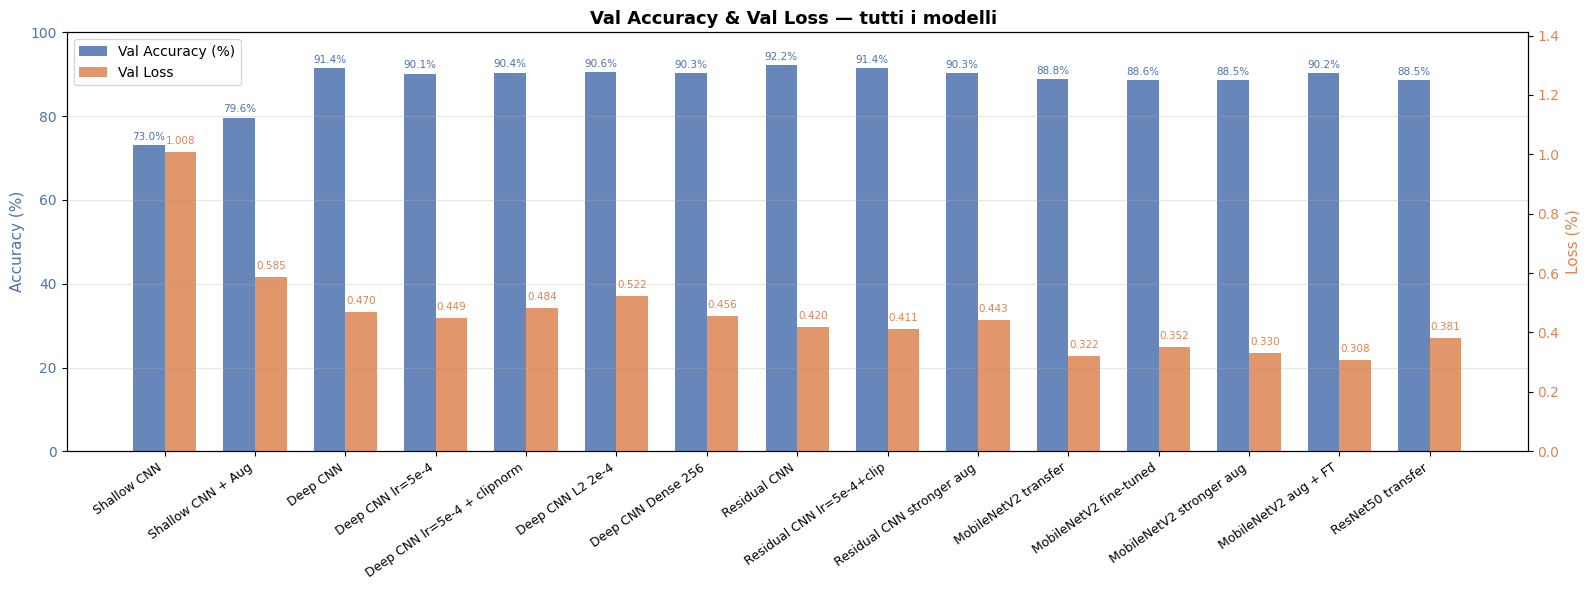

In [46]:

import math

# ── dizionario history per ogni modello ──────────────────────────────
# Adatta i nomi delle variabili history ai tuoi (es. history_1, h1, ecc.)
model_histories = {
    "Shallow CNN":                  history_1,
    "Shallow CNN + Aug":            history_1_aug,
    "Deep CNN":                     history_2,
    "Deep CNN lr=5e-4":             history_2_lr_5e4,
    "Deep CNN lr=5e-4 + clipnorm":  history_2_clip,
    "Deep CNN L2 2e-4":             history_2_l2_2e4,
    "Deep CNN Dense 256":           history_2_dense_256,
    "Residual CNN":                 history_3,
    "Residual CNN lr=5e-4+clip":    history_3_clip,
    "Residual CNN stronger aug":    history_3_stronger_aug,
    "MobileNetV2 transfer":         history_4,
    "MobileNetV2 fine-tuned":       history_4_ft,
    "MobileNetV2 stronger aug":     history_4_aug,
    "MobileNetV2 aug + FT":         history_4_aug_ft,
    "ResNet50 transfer":            history_5,
}

# ── estrai i valori finali di val_loss e val_accuracy da ogni history ──
final_val_loss = []
final_val_acc  = []
model_names    = []

for model_name, h in model_histories.items():
    if hasattr(h, "history"):               # Keras
        loss = h.history["val_loss"][-1]
        acc  = h.history["val_accuracy"][-1] * 100
    else:                                   # PyTorch
        loss = h["vl"][-1]
        acc  = h["va"][-1] * 100

    model_names.append(model_name)
    final_val_loss.append(loss)
    final_val_acc.append(acc)

# ── istogramma a barre raggruppate ────────────────────────────────────
x      = np.arange(len(model_names))
width  = 0.35

fig, ax1 = plt.subplots(figsize=(16, 6))

bars_acc  = ax1.bar(x - width/2, final_val_acc,  width, label="Val Accuracy (%)", color="#4C72B0", alpha=0.85)
ax1.set_ylabel("Accuracy (%)", color="#4C72B0", fontsize=11)
ax1.set_ylim(0, 100)
ax1.tick_params(axis="y", labelcolor="#4C72B0")

# secondo asse Y per la loss (scala diversa)
ax2 = ax1.twinx()
bars_loss = ax2.bar(x + width/2, final_val_loss, width, label="Val Loss",         color="#DD8452", alpha=0.85)
ax2.set_ylabel("Loss (%)", color="#DD8452", fontsize=11)
ax2.set_ylim(0, max(final_val_loss) * 1.4)
ax2.tick_params(axis="y", labelcolor="#DD8452")

# etichette sopra le barre
for bar, val in zip(bars_acc, final_val_acc):
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8,
             f"{val:.1f}%", ha="center", va="bottom", fontsize=7.5, color="#4C72B0")

for bar, val in zip(bars_loss, final_val_loss):
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + max(final_val_loss) * 0.02,
             f"{val:.3f}", ha="center", va="bottom", fontsize=7.5, color="#DD8452")

ax1.set_xticks(x)
ax1.set_xticklabels(model_names, rotation=35, ha="right", fontsize=9)
ax1.set_title("Val Accuracy & Val Loss — tutti i modelli ", fontweight="bold", fontsize=13)

# legenda unificata
lines = [bars_acc, bars_loss]
labels = ["Val Accuracy (%)", "Val Loss"]
ax1.legend(lines, labels, loc="upper left", fontsize=10)

ax1.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "accuracy_loss_grouped.png"), dpi=120, bbox_inches="tight")
plt.show()
plt.show()


## 20. Confusion matrix and error analysis


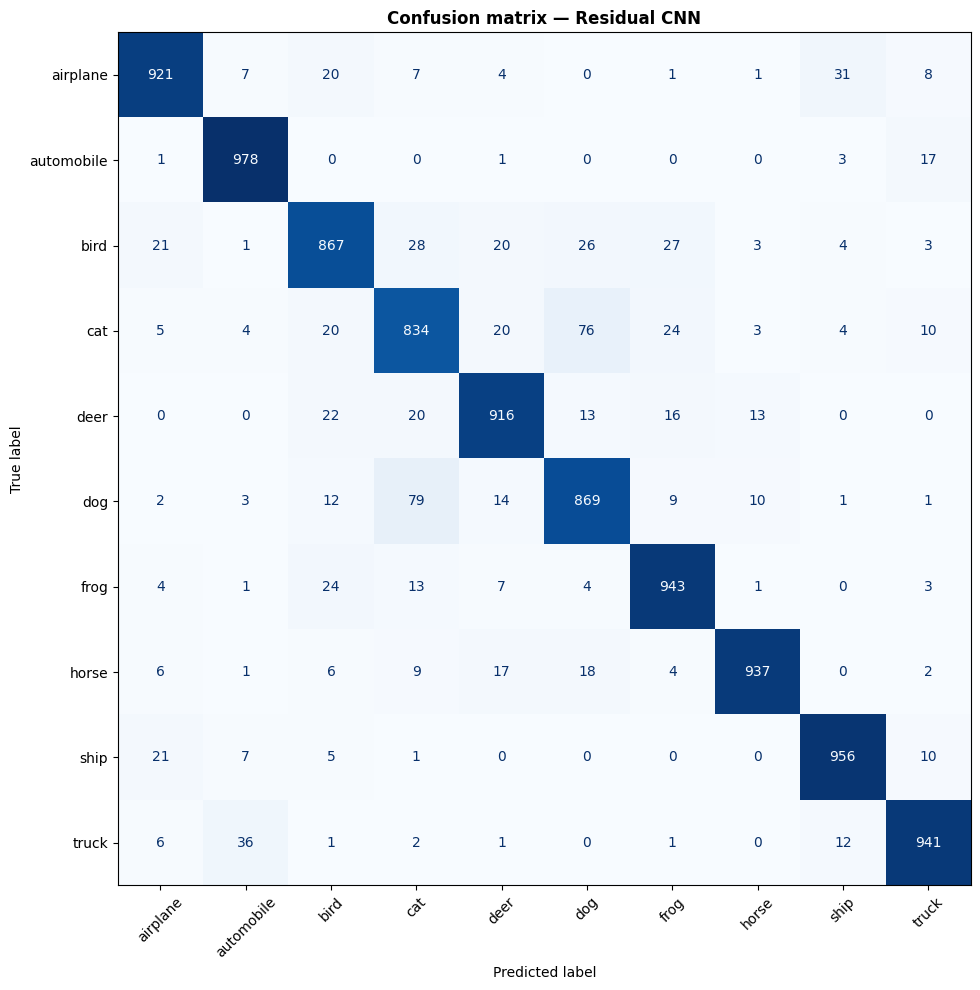

In [35]:
def plot_confusion_matrix(y_true, y_pred, class_names, title="Confusion matrix"):
    cm = confusion_matrix(y_true, y_pred)

    fig, ax = plt.subplots(figsize=(10, 10))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)

    ax.set_title(title, fontweight="bold")
    plt.tight_layout()

    filename = title.replace(" ", "_").replace("—", "-").lower() + ".png"
    plt.savefig(os.path.join(OUT_DIR, filename), dpi=120, bbox_inches="tight")
    plt.show()


plot_confusion_matrix(
    y_test,
    best_preds,
    class_names,
    title=f"Confusion matrix — {best_model_name}"
)


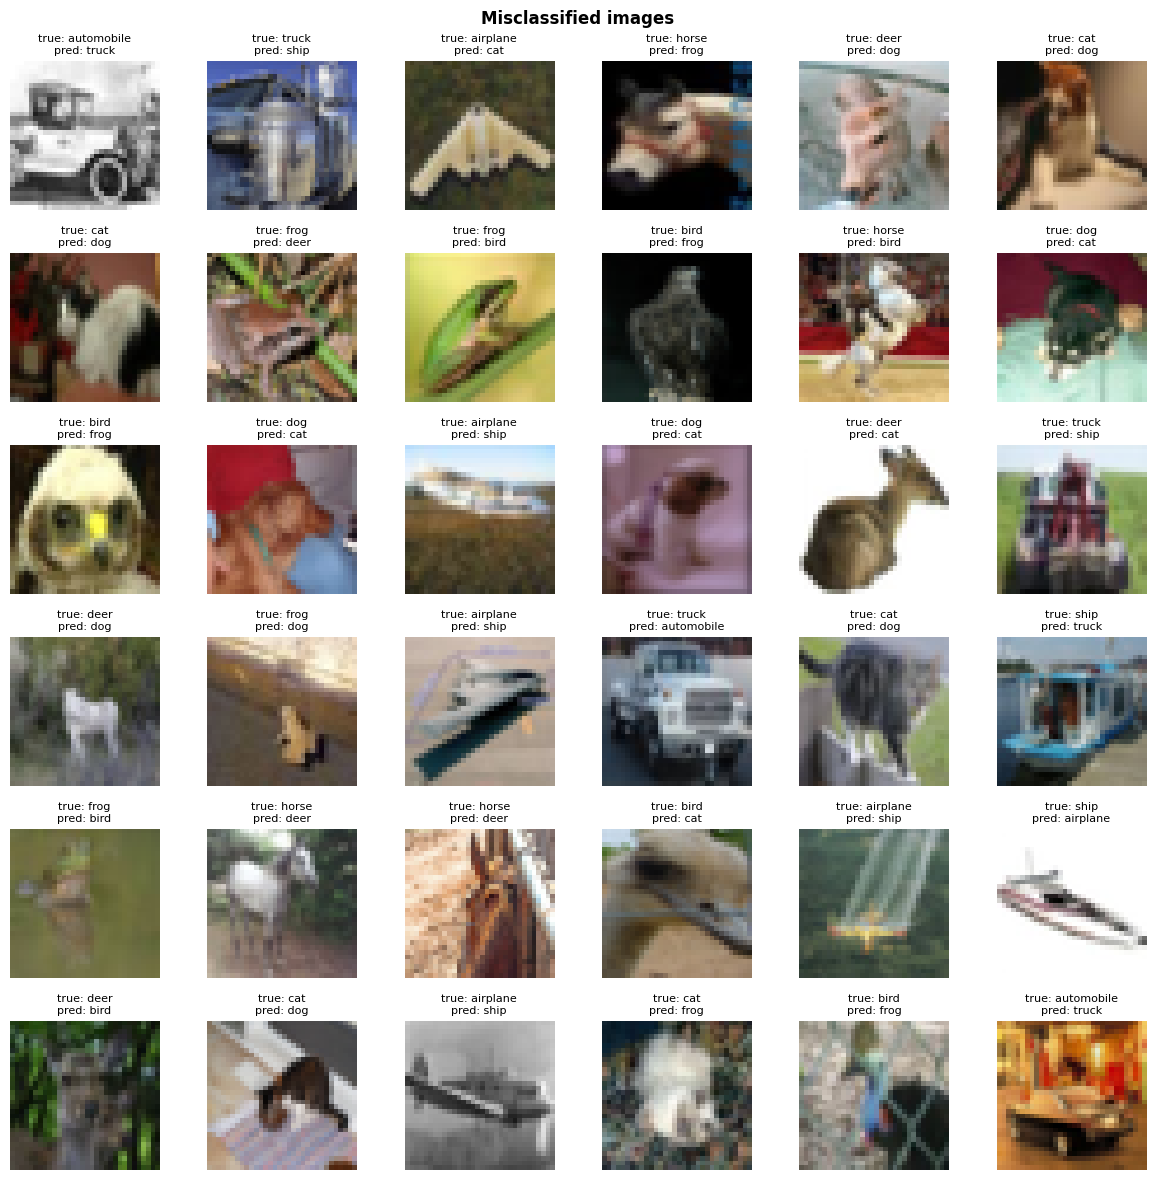

In [36]:
def show_misclassified_images(x, y_true, y_pred, class_names, n=36):
    wrong = np.where(y_true != y_pred)[0]
    selected = wrong[:n]
    rows = int(np.ceil(n / 6))

    plt.figure(figsize=(12, 2 * rows))
    for i, idx in enumerate(selected):
        ax = plt.subplot(rows, 6, i + 1)
        ax.imshow(x[idx].astype("uint8"))
        ax.set_title(
            f"true: {class_names[y_true[idx]]}\npred: {class_names[y_pred[idx]]}",
            fontsize=8
        )
        ax.axis("off")

    plt.suptitle("Misclassified images", fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "misclassified_images.png"), dpi=120, bbox_inches="tight")
    plt.show()


show_misclassified_images(
    x_test,
    y_test,
    best_preds,
    class_names
)


## 21. Saving final models


In [1]:
models_to_save = {
    "model_1": "model_1_shallow_cnn.keras",
    "model_1_aug": "model_1b_shallow_cnn_aug.keras",
    "model_2": "model_2_deep_cnn.keras",
    "model_2_clip": "model_2_deep_cnn_lr_5e4_clipnorm.keras",
    "model_3": "model_3_residual_cnn.keras",
    "model_3_clip": "model_3_residual_cnn_lr_5e4_clipnorm.keras",
    "model_4": "model_4_mobilenetv2_transfer_or_finetuned.keras",
    "model_4_aug": "model_4_mobilenetv2_stronger_aug_finetuned.keras",
    "model_5": "model_5_resnet50_transfer.keras",
}

for model_var, filename in models_to_save.items():
    if model_var in globals():
        globals()[model_var].save(os.path.join(OUT_DIR, filename))
        print(f"Saved {filename}")

print("Models saved in", OUT_DIR)


NameError: name 'OUT_DIR' is not defined